# Sentinel-3/OLCI Cal/Val monitoring at the top of atmosphere with RadCalNet-OC

This notebook simulates the top-of-atmosphere (TOA) radiance of the Sentinel-3A and Sentinel-3B OLCI overpasses of
the RadCalNet water sites with the **current version of `radcalnet_oc`**, from the co-located AERONET-OC
measurements, and monitors the ratio OLCI / simulation band by band, site by site and platform by platform.

| RadCalNet code | site | AERONET-OC station(s) |
|---|---|---|
| **VEIT** | Acqua Alta Oceanographic Tower (Venice, Adriatic Sea) | `AAOT` (since 2017-10), `Venise` (until 2023-03) |
| **GABU** | Galata platform (Black Sea) | `Galata_Platform` |
| **CORO** | Section-7 platform (Black Sea) | `Section-7_Platform` |

**What the outputs mean.** The objective of RadCalNet-OC is an accurate TOA simulator. The matchups are used here as
*evidence* of the uncertainty of the simulation: a ratio $L_{OLCI}/L_{sim}$ is read against the uncertainty budget
of the simulation (and of the OLCI measurement), and the flags (sunglint, viewing angle, aerosol load,
water-reflectance quality, spatial heterogeneity) are *uncertainty indicators* that tell when a simulation is too
uncertain for Cal/Val. The ratios are not a score to optimise, and no coefficient is tuned on them.

**Outline**

1. Setup: package version and effective model settings
2. Configuration: sites, period, platforms, matchup criteria, model settings, solar irradiance
3. Data inventory of each site (OLCI subsets, AERONET-OC coverage, overlap)
4. OLCI spectral responses and solar irradiance consistency
5. AERONET-OC inputs
6. Extraction and screening of the OLCI pixels (L1 flags, OmniCloudMask, homogeneity, platform pixel)
7. Simulations with the current model at the exact OLCI geometry (cached per scene), direct sunglint, uncertainty budget
8. Matchup dataset: ratios and their uncertainty
9. Monitoring: spectra, time series with the uncertainty bands, per-band summary, drift, S3A/S3B consistency
10. Absorption-band diagnostics (O$_2$-A, O$_2$-B, H$_2$O)
11. Flags and selections as uncertainty indicators
12. Export of the matchup dataset
13. Notes and open issues

`QUICK = True` (section 2) runs a short test (one site, three months); set it to `False` for the multi-year,
three-site monitoring (the simulations are cached per scene, so the full run is incremental).

## 1. Setup

The simulations are computed in this notebook with the installed `radcalnet_oc` (editable install of the
repository): the version, the git commit and the effective settings of `Process` are printed below and written in
the attributes of every cached simulation and of the exported matchup file.

In [1]:
import glob
import logging
import os
import warnings
import zipfile

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats
import xarray as xr
from joblib import Parallel, delayed

rc = {'font.family': 'serif', 'mathtext.fontset': 'stix'}
plt.rcParams.update(rc)
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']
plt.rcParams.update({'font.size': 16, 'axes.labelsize': 18})
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import aeronet_oc_db
import radcalnet_oc as radoc
from radcalnet_oc import coxmunk
from radcalnet_oc.process import package_version
from radcalnet_oc.reconstruction import Reconstruction
from radcalnet_oc.uncertainty import INPUT_UNC, uncertainty_budget

logging.getLogger('radcalnet_oc').setLevel(logging.WARNING)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='A worker stopped')            # restarts of the joblib workers
warnings.filterwarnings('ignore', message='This axis already has a converter')
warnings.filterwarnings('ignore', message='Patch size too large')       # OmniCloudMask on small subsets
opj = os.path.join
print(f'radcalnet_oc {radoc.__version__} ({package_version()})')

radcalnet_oc 1.2.0 (1.2.0+g5055a72)


## 2. Configuration

### Sites

Each site gives its AERONET-OC station(s) and level(s), the folder of the OLCI L1 subsets (one netCDF file per
overpass, `<root>/OLCI_<A|B>/<yyyy>/<mm>/<dd>/OLCI_<A|B>_Datacube_<start time>.nc`, made by the datacube
generator from the EFR products of processing baseline 004) or the zip archive that holds them, and the matchup
window. The coordinates come from the AERONET-OC catalogue (`aeronet_oc_db.site_info`).

* **Levels.** Level 2.0 by default; CORO also uses level 1.5 (level 2.0 stops in 2024-08), as in the
  Sentinel-2 statements. When a measurement exists at both levels, level 2.0 is kept; the level of each
  measurement is carried to the matchups (selection of section 11).
* **Window.** A box of $(2h+1)^2$ OLCI pixels (300 m) centred on the pixel nearest to the station, `half_box`
  $h = 1$, i.e. $900\times900$ m$^2$, and a neighbourhood of $15\times15$ pixels (4.5 km) for the cloud fraction.
* **Platform pixel.** The Sentinel-2 ROI study (`scripts/s2_toa_matchup/roi_selection.py`) found that the
  footprint of the platforms vanishes 60-100 m from the structure; the structure covers a small part of the OLCI
  pixel that contains the station. `exclude_station_pixel` removes this pixel from the box; by default it is kept
  and the effect of its removal is quantified in section 11 (it is an uncertainty indicator, not a correction).

In [2]:
QUICK = True                      # short test: first site of QUICK_SITES, QUICK_PERIOD

SITES = {
    'VEIT': dict(name='Acqua Alta Oceanographic Tower (Venice)',
                 aeronet=['AAOT', 'Venise'], levels=['lev20'],
                 s3_root='/data/satellite/sentinel3/Venice', s3_zip=None,
                 half_box=1, exclude_station_pixel=False),
    'GABU': dict(name='Galata platform (Black Sea)',
                 aeronet=['Galata_Platform'], levels=['lev20'],
                 s3_root='/data/satellite/sentinel3/Galata', s3_zip=None,
                 half_box=1, exclude_station_pixel=False),
    'CORO': dict(name='Section-7 platform (Black Sea)',
                 aeronet=['Section-7_Platform'], levels=['lev20', 'lev15'],
                 s3_root='/data/satellite/sentinel3/CORO', s3_zip='/data/satellite/sentinel3/CORO.zip',
                 half_box=1, exclude_station_pixel=False),
}
SITE_CODES = list(SITES)                      # sites of the monitoring (all three by default)
PERIOD = slice('2016-04-01', '2026-12-31')
PLATFORMS = {'S3A': 'tab:blue', 'S3B': 'tab:red'}

QUICK_SITES = ['VEIT']
QUICK_PERIOD = slice('2020-06-01', '2020-08-31')
if QUICK:
    SITE_CODES, PERIOD = QUICK_SITES, QUICK_PERIOD

# matchup criteria
DELTA_TIME = np.timedelta64(60, 'm')          # AERONET-OC measurements within +/- 1 h of the overpass
HALF_NEIGHBOURHOOD = 7                        # 15 x 15 pixels for the cloud fraction
MAX_DISTANCE = 300.                           # m, station to the nearest pixel centre
MAX_CLOUD_FRACTION = 0.05                     # in the neighbourhood (OmniCloudMask and the 'bright' flag)
MAX_CV, CV_BAND = 0.05, 'Oa17'                # coefficient of variation in the box (865 nm)
VZA_MAX, SZA_MAX = 48., 70.                   # deg; viewing angles of the TOA LUT up to 48.9 deg
USE_OCM = True                                # OmniCloudMask on the subset (needs the omnicloudmask package)
REJECT_FLAGS = ['land', 'coastline', 'invalid', 'saturated', 'partially_saturated', 'dubious', 'cosmetic',
                'straylight_risk', 'bright']  # OLCI L1 flags rejected in the box ('sun-glint_risk' and
                                              # 'duplicated' are not used: the glint is simulated and flagged)

# outputs: per-scene caches (OLCI extraction, simulations) and matchup files, one folder per radcalnet_oc version
ODIR = os.environ.get('S3_CALVAL_ODIR', f'/data/radcalnet/matchups/sentinel3/v{radoc.__version__}')
EXTRACT_DIR = os.environ.get('S3_CALVAL_EXTRACT_DIR', '/data/satellite/sentinel3')  # where CORO.zip members go
N_JOBS = int(os.environ.get('S3_CALVAL_N_JOBS', 2))   # parallel simulations (about 0.6-1 GB each)
SAVE = True                                   # export the matchup dataset (section 12)
print(f'sites {SITE_CODES}, period {PERIOD.start} to {PERIOD.stop}, outputs in {ODIR}')

sites ['VEIT'], period 2020-06-01 to 2020-08-31, outputs in <quick-run test folder, S3_CALVAL_ODIR>


### Model settings

The settings of the simulation are stated explicitly (they are the defaults of version 1.2):

| setting | value | meaning |
|---|---|---|
| `gas_coupling` | `'path_length'` | per-term gaseous transmittances of the scattered light, photon path-length model fitted on SOS-ABS, $T = (1 + s^2\eta\tau)^{-1/s^2}$ |
| `o2_model` | `'lbl'` | line-by-line O$_2$ in the O$_2$-B and O$_2$-A bands |
| `rrs_extension` | `'pure_water'` | $R_{rs}$ beyond the reconstructed range from the pure-water model |
| `rayleigh_pressure` | `True` | Rayleigh scattering scaled to the surface pressure of the measurement |
| `solar_database` | `'tsis'` | TSIS-1 hybrid solar reference spectrum for $F_0$ (see below) |
| sunglint | `'cm_iso_mix'` | direct sunglint $T_{dir}R_{sg}$ with the heavy-tailed isotropic slope statistics (`Process.compute_sunglint`), glint flags `GLINT_FLAGS` |
| budget | `INPUT_UNC` | provisional input uncertainties propagated through `Process`, glint ensemble, model gap (`uncertainty_budget`) |

The wavelength interpolation of the look-up tables (log-log quadratic for the path reflectance) is not a setting.

The TOA reflectance of the simulation is (`docs/source/methods.rst`)

$$
R_{toa}(\lambda) = \frac{\pi\, t^{\uparrow}(\lambda)\, L_w^{*}(\lambda)}{E_0(\lambda)} + T_g^{atm}(\lambda)\, R_{atm}(\lambda)
+ T_{dir}(\lambda)\, R_{sg}, \qquad E_0 = \mu_0\, d^2(J)\, F_0 ,
$$

where the direct sunglint $T_{dir}R_{sg}$ is computed separately from the look-up tables (`Rglint`, `Rtoa_glint`).

### Solar irradiance and consistency of radiance and reflectance

OLCI L1 delivers a calibrated **radiance**; the in-band solar flux of the product (`solar_flux`, per detector,
seasonally corrected) only serves to convert it to a reflectance and comes from the Thuillier spectrum of the OLCI
characterisation database. The comparison is therefore made **in radiance**:

$$
L^{b}_{sim} = \frac{1}{\pi}\,\frac{\int R_{toa}(\lambda)\, E_0(\lambda)\, S_b(\lambda)\, d\lambda}{\int S_b(\lambda)\, d\lambda},
\qquad r_b = \frac{L^{b}_{OLCI}}{L^{b}_{sim}} ,
$$

which depends on the solar spectrum of the *simulation* only (its absolute uncertainty, about 0.5 % for TSIS-1, is
part of the comparison), not on the solar flux of the OLCI product. A comparison in reflectance,
$\rho_{OLCI} = \pi L_{OLCI}/(\mu_0 F^{b}_{OLCI})$ against the $E_0$-weighted band reflectance of the simulation, would
give $r_b^{\rho} = r_b\, \bar E^{b}_{0,sim} / (\mu_0 F^{b}_{OLCI})$: it differs by the ratio of the two in-band solar
irradiances, which section 4 computes. `SOLAR_DATABASE = 'thuillier2003'` (Thuillier et al. 2003 composite,
the spectrum of the Sentinel-2 L1C) brings the simulation close to the OLCI solar flux; the ATLAS3 spectrum of
`'thuillier'` is 1.4 % higher.

In [3]:
MODEL = dict(gas_coupling='path_length', o2_model='lbl', rrs_extension='pure_water', rayleigh_pressure=True,
             solar_database='tsis')
SUNGLINT = 'cm_iso_mix'          # slope statistics of the direct sunglint (Process.compute_sunglint)
BUDGET = True                    # uncertainty budget of each scene (12 more runs, nearest measurement)
BUDGET_INPUTS = INPUT_UNC        # provisional input uncertainties of radcalnet_oc.uncertainty

# effective settings: an empty Process (clear-water template) with these settings
_p = radoc.Process(**MODEL)
SETTINGS = {**_p.provenance(), 'sunglint_stats': SUNGLINT, 'glint_levels': str(coxmunk.GLINT_LEVELS),
            'glint_angle_min': coxmunk.GLINT_ANGLE_MIN, 'budget': str(BUDGET),
            'budget_inputs': repr(BUDGET_INPUTS)}
SIM_WL = _p.full_wl.sel(wl=slice(370, 1060)).values        # spectral grid of the simulation in the OLCI range
del _p
pd.Series(SETTINGS, name='effective settings').to_frame()

,effective settings
radcalnet_oc_version,1.2.0+g5055a72
o2_model,lbl
gas_coupling,path_length
gas_coupling_table,gas_coupling_ppld.csv
rrs_extension,pure_water
rayleigh_pressure,1
solar_database,tsis
default_wind,2.0
toa_lut,toa_lut_opac_wind_v3.nc
toa_lut_doi,10.5281/zenodo.23394202


## 3. Data inventory

For each site: the OLCI subsets (from the folder, or listed in the zip archive when the folder does not exist), the
AERONET-OC coverage of each station and level, and the overlap of the two. A site without data is kept in the
configuration, and the table says what is missing.

```{note}
**CORO.** The OLCI subsets of Section-7 are only in `/data/satellite/sentinel3/CORO.zip` (16 GB, 2019-2026).
The notebook extracts the members it needs (matchup candidates only) into `EXTRACT_DIR/CORO/...`; to extract
the whole archive once: `cd /data/satellite/sentinel3 && unzip -n CORO.zip`.
```

In [4]:
def site_coordinates(code):
    '''Latitude and longitude of the first AERONET-OC station of the site (catalogue of aeronet_oc_db).'''
    info = aeronet_oc_db.site_info(level='lev15')
    station = SITES[code]['aeronet'][0]
    return float(info.loc[station, 'latitude']), float(info.loc[station, 'longitude'])


def olci_inventory(code):
    '''OLCI subsets of a site: DataFrame (index: start time of the product) with platform, path and source.'''
    cfg = SITES[code]
    pattern = 'OLCI_[AB]/[0-9]*/[0-9]*/[0-9]*/OLCI_*_Datacube_*.nc'
    files = sorted(glob.glob(opj(cfg['s3_root'], pattern)))
    source = 'folder'
    if not files and cfg.get('s3_zip') and os.path.exists(cfg['s3_zip']):
        with zipfile.ZipFile(cfg['s3_zip']) as z:
            files = sorted(n for n in z.namelist() if n.endswith('.nc') and '_Datacube_' in n)
        source = 'zip'
    rows = []
    for f in files:
        _, unit, _, stamp = os.path.basename(f)[:-3].split('_')
        rows.append(dict(time=pd.Timestamp(stamp), platform=f'S3{unit}', path=f, source=source))
    if not rows:
        return pd.DataFrame(columns=['platform', 'path', 'source'], index=pd.DatetimeIndex([], name='time'))
    return pd.DataFrame(rows).set_index('time').sort_index()


def local_path(code, row):
    '''Path of a subset on disk; members of the zip archive are extracted on demand into EXTRACT_DIR.'''
    if row['source'] == 'folder':
        return row['path']
    target = opj(EXTRACT_DIR, row['path'])
    if not os.path.exists(target):
        with zipfile.ZipFile(SITES[code]['s3_zip']) as z:
            z.extract(row['path'], EXTRACT_DIR)
    return target


_AERONET_CACHE = {}


def open_aeronet(station, level):
    '''AERONET-OC dataset of a station (aeronet_oc_db), kept in memory (opening a site takes tens of seconds).'''
    if (station, level) not in _AERONET_CACHE:
        _AERONET_CACHE[station, level] = aeronet_oc_db.open_site(station, level, legacy_names=True).load()
    return _AERONET_CACHE[station, level]


def aeronet_coverage(code):
    rows = []
    for station in SITES[code]['aeronet']:
        for level in SITES[code]['levels']:
            try:
                t = open_aeronet(station, level).time.values
                rows.append(dict(site=code, station=station, level=level, n=len(t),
                                 start=str(t.min())[:10], end=str(t.max())[:10]))
            except Exception as e:     # station or level missing in the database
                rows.append(dict(site=code, station=station, level=level, n=0, start='', end=f'missing ({e})'))
    return rows


inventory, coverage = {}, []
for code in SITES:                      # all the configured sites, also those not monitored in this run
    inv = olci_inventory(code)
    inventory[code] = inv
    for r in aeronet_coverage(code):
        if len(inv):
            t = pd.to_datetime(inv.index)
            overlap = ((t >= pd.Timestamp(r['start'])) & (t <= pd.Timestamp(r['end']) + pd.Timedelta('1D'))).sum() \
                if r['n'] else 0
        else:
            overlap = 0
        coverage.append({**r, 'OLCI source': inv.source.iloc[0] if len(inv) else 'MISSING',
                         'OLCI S3A': int((inv.platform == 'S3A').sum()), 'OLCI S3B': int((inv.platform == 'S3B').sum()),
                         'OLCI first': str(inv.index.min())[:10] if len(inv) else '',
                         'OLCI last': str(inv.index.max())[:10] if len(inv) else '',
                         'OLCI scenes in AERONET-OC period': int(overlap)})
coverage = pd.DataFrame(coverage).set_index(['site', 'station', 'level'])
coverage

n       start         end OLCI source  \
site station            level                                              
VEIT AAOT               lev20  22520  2017-10-23  2025-07-16      folder   
     Venise             lev20  11421  2002-04-20  2023-03-12      folder   
GABU Galata_Platform    lev20   9531  2014-04-14  2023-12-19      folder   
CORO Section-7_Platform lev20  10240  2019-08-27  2024-08-18         zip   
                        lev15  27536  2019-08-27  2026-11-13         zip   

                               OLCI S3A  OLCI S3B  OLCI first   OLCI last  \
site station            level                                               
VEIT AAOT               lev20      2035      1442  2016-04-06  2025-12-31   
     Venise             lev20      2035      1442  2016-04-06  2025-12-31   
GABU Galata_Platform    lev20      1960      1385  2016-04-06  2025-12-31   
CORO Section-7_Platform lev20      1737      1642  2019-08-27  2026-10-18   
                        lev15      1737      1642  2019-08-27  2026-10-18   

                               OLCI scenes in AERONET-OC period  
site station            level                                    
VEIT AAOT               lev20                              2911  
     Venise             lev20                              2352  
GABU Galata_Platform    lev20                              2558  
CORO Section-7_Platform lev20                              2356  
                        lev15                              3379

## 4. OLCI spectral responses and solar irradiance

The spectral responses are those of the S3A characterisation (`notebook/flex/S3A_OL_SRF_20160713_mean_rsr.nc4`,
mean over the cameras). No S3B response file is available in the repository: for both platforms, the response
$S_b$ is shifted to the characterised central wavelength $\lambda_0$ of the detectors that observed the box
(`lambda0` per detector and `detector_index` per pixel of the L1 product), i.e.
$S_b(\lambda) = S_b^{S3A}(\lambda - \lambda_{0,b} + \lambda^{S3A}_{c,b})$ with $\lambda^{S3A}_{c,b}$ the centre of the
tabulated response. The shape of the S3B responses is assumed to be that of S3A (an approximation in the
absorption bands, section 10). The band integrals are computed on the spectral grid of the simulation (about
0.1 nm, from the gaseous absorption LUT), as with `Spectral.from_srf`, whose response-weighted centres are shown
below.

**Solar irradiance.** In-band solar irradiance at the mean Earth-Sun distance, $\bar F^{b}_0 = \int F_0 S_b\,d\lambda / \int S_b\,d\lambda$,
of the solar spectra of `radcalnet_oc` against that of the OLCI characterisation (`solar_irradiance` of the SRF
file, Thuillier): the ratio is the factor between a comparison in radiance and one in reflectance.

In [5]:
SRF_FILE = '../flex/S3A_OL_SRF_20160713_mean_rsr.nc4'      # relative to notebook/sentinel3
if not os.path.exists(SRF_FILE):                            # notebook run from another folder
    SRF_FILE = opj(os.path.dirname(radoc.__file__), '..', 'notebook', 'flex', os.path.basename(SRF_FILE))
srf_ds = xr.open_dataset(SRF_FILE)
OLCI_BANDS = [f'Oa{i + 1:02d}' for i in range(srf_ds.sizes['band_number'])]
SRF_WL = srf_ds.mean_spectral_response_function_wavelength.values.astype(float)     # (band, 200)
SRF_VAL = np.clip(np.nan_to_num(srf_ds.mean_spectral_response_function.values.astype(float)), 0, None)
SRF_CENTRE = srf_ds.srf_centre_wavelength.values.astype(float)
NOMINAL_WL = dict(zip(OLCI_BANDS, srf_ds.nominal_centre_wavelength.values.round(1)))


def srf_matrix(wl, centre=None):
    '''Spectral responses (band, wl) on the grid ``wl``, shifted to the central wavelengths ``centre`` (nm).'''
    shift = np.zeros(len(OLCI_BANDS)) if centre is None else np.asarray(centre) - SRF_CENTRE
    return np.array([np.interp(wl, SRF_WL[b] + shift[b], SRF_VAL[b], left=0, right=0) for b in range(len(OLCI_BANDS))])


def band_average(x, wl, S, weight=None):
    '''Band average of x(..., wl) with the responses S (band, wl) and an optional weight (..., wl).'''
    w = S if weight is None else S * weight[..., None, :]
    return np.trapezoid(x[..., None, :] * w, wl, axis=-1) / np.trapezoid(w, wl, axis=-1)


spectral = radoc.Spectral.from_srf(xr.DataArray(srf_matrix(SIM_WL), coords={'band': OLCI_BANDS, 'wl': SIM_WL},
                                                dims=('band', 'wl')))
solar = radoc.SolarIrradiance()
S = srf_matrix(SIM_WL)
tab = pd.DataFrame({'nominal (nm)': NOMINAL_WL, 'SRF centre (nm)': dict(zip(OLCI_BANDS, SRF_CENTRE.round(2))),
                    'Spectral.from_srf centre (nm)': dict(zip(OLCI_BANDS, spectral.central_wl.round(2))),
                    'F0 OLCI char.': dict(zip(OLCI_BANDS, srf_ds.solar_irradiance.values.round(1)))})
for db in ['tsis', 'thuillier2003', 'thuillier']:
    F0 = solar.__dict__[db].interp(wl=SIM_WL).values
    tab[f'{db} / OLCI'] = band_average(F0, SIM_WL, S) / srf_ds.solar_irradiance.values
tab.round(4).T

,Oa01,Oa02,Oa03,Oa04,Oa05,Oa06,Oa07,Oa08,Oa09,Oa10,...,Oa12,Oa13,Oa14,Oa15,Oa16,Oa17,Oa18,Oa19,Oa20,Oa21
nominal (nm),400.000000,412.5000,442.5000,490.000000,510.000000,560.000000,620.000000,665.000000,673.799988,681.200012,...,753.799988,761.200012,764.400024,767.500000,778.799988,865.000000,885.000000,900.000000,940.000000,1020.000000
SRF centre (nm),400.300000,411.8500,442.9600,490.490000,510.470000,560.450000,620.410000,665.270000,674.030000,681.570000,...,754.180000,761.730000,764.820000,767.920000,779.260000,865.430000,884.310000,899.310000,938.970000,1015.800000
Spectral.from_srf centre (nm),400.300000,411.8500,442.9600,490.490000,510.470000,560.450000,620.410000,665.270000,674.030000,681.570000,...,754.180000,761.730000,764.820000,767.920000,779.260000,865.430000,884.310000,899.310000,938.970000,1015.800000
F0 OLCI char.,1513.599976,1708.0000,1890.0000,1936.300049,1919.599976,1796.900024,1649.099976,1530.199951,1494.699951,1468.900024,...,1266.300049,1247.500000,1239.000000,1229.800049,1173.500000,959.700012,930.900024,895.799988,826.400024,699.700012
tsis / OLCI,0.963800,1.0330,1.0031,1.005900,1.017900,1.031100,1.016300,1.012500,1.015300,1.016700,...,0.990200,0.989700,0.986200,0.983800,1.010600,0.995000,0.994500,1.001000,0.998000,1.004200
thuillier2003 / OLCI,1.000000,1.0000,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
thuillier / OLCI,0.964300,1.0236,1.0116,1.008200,0.998300,1.025900,1.019000,1.008500,1.029800,1.021100,...,1.010500,0.998200,0.995700,0.996800,1.014300,1.022200,1.014000,1.014000,1.014000,1.014000


## 5. AERONET-OC inputs

The input variables of `Process` are taken from each AERONET-OC measurement (gas columns, pressure, wind, spectral
AOT, $L_{wn}$-based $R_{rs}$), as in the Sentinel-2 matchups (`scripts/s2_toa_matchup/s2_toa_matchup.py`). The
stations and levels of a site are merged; for a measurement present at both levels, level 2.0 is kept.

In [6]:
LEVEL_VALUE = {'lev20': 2.0, 'lev15': 1.5}


def aeronet_inputs(station, level):
    '''AERONET-OC measurements of a station with the input variables of radcalnet_oc (time series).'''
    ds = open_aeronet(station, level).sortby('wl')
    aod = ds['Aerosol_Optical_Depth'].interpolate_na('wl')
    out = xr.Dataset(coords={'time': ds.time})
    out['tcwv'] = ds['Total_Precipitable_Water(cm)'] * 10            # kg m-2
    out['tco3'] = ds['Total_Ozone(Du)'] * 2.14485e-5                  # kg m-2
    out['tcno2'] = ds['Total_NO2(DU)'] * 2.055482e-5                  # kg m-2
    out['pressure'] = ds['Pressure(hPa)']
    out['wind'] = ds['Wind_Speed(ms)']
    out['aot550'] = aod.interp(wl=550)
    out['aot865'] = aod.interp(wl=865)
    out['ang_exp'] = -np.log(out.aot550 / out.aot865) / np.log(550 / 865)
    out['naot'] = (ds['Aerosol_Optical_Depth'] / out.aot550).rename({'wl': 'wl_aeronet'})
    out['chl'] = ds['Chlorophyll-a']
    out['sza_aeronet'] = ds['SZA']
    out['Rrs_Lwn'] = ds['Rrs_Lwn']
    out = out.reset_coords(drop=True).dropna('time', subset=['aot550'])
    out['level'] = ('time', np.full(out.sizes['time'], LEVEL_VALUE[level]))
    return out


def site_inputs(code, period=None):
    '''Merged AERONET-OC inputs of the stations and levels of a site.'''
    parts = []
    for station in SITES[code]['aeronet']:
        for level in SITES[code]['levels']:
            try:
                x = aeronet_inputs(station, level)
            except Exception as e:
                print(f'{code}: {station} {level} not available ({e})')
                continue
            x = x.sel(time=period) if period is not None else x
            parts.append(x.load())
    if not parts:
        return None
    ds = xr.concat(parts, 'time', join='outer').sortby('time')
    # duplicates (two stations or two levels at the same time): keep the highest level
    order = np.lexsort((-ds.level.values, ds.time.values))
    ds = ds.isel(time=order)
    _, first = np.unique(ds.time.values, return_index=True)
    ds = ds.isel(time=np.sort(first))
    # the stations have different bands (AAOT and Venise): normalised AOT interpolated on the union of the bands
    ds['naot'] = ds.naot.interpolate_na('wl_aeronet')
    return ds


aeronet = {}
for code in SITE_CODES:
    aeronet[code] = site_inputs(code, PERIOD)
    a = aeronet[code]
    print(f'{code}: {0 if a is None else a.sizes["time"]} AERONET-OC measurements in the period'
          + ('' if a is None else f' (level 2.0: {int((a.level == 2).sum())}, level 1.5: {int((a.level == 1.5).sum())})'))

VEIT: 1130 AERONET-OC measurements in the period (level 2.0: 1130, level 1.5: 0)


## 6. Extraction and screening of the OLCI pixels

**Candidates.** A subset is a candidate when AERONET-OC measurements exist within $\pm\Delta t$ of its start time
(plus the 3 min of the product); only the candidates are opened.

**Extraction** (cached per scene in `ODIR/olci/<code>/`): pixel nearest to the station, box of $(2h+1)^2$ pixels and
neighbourhood of $15\times15$ pixels; overpass time from the time stamp of the image line of the station; geometry
(mean of the box); radiance and its uncertainty (`radiance_unc`, $\log_{10}$ of the standard uncertainty in
mW m$^{-2}$ sr$^{-1}$ nm$^{-1}$); $\lambda_0$, FWHM and solar flux of the detectors of the box; OLCI L1 flags
(decoded from `flag_masks`, `flag_meanings`); OmniCloudMask (red, green and NIR TOA reflectances of the subset;
0 clear, 1 thick cloud, 2 thin cloud, 3 shadow).

**Screening**: box free of the `REJECT_FLAGS`, cloud fraction in the neighbourhood below 5 % (OmniCloudMask and the
`bright` flag), $\theta_v \le 48°$ and $\theta_0 < 70°$, coefficient of variation in the box below 5 % at 865 nm.
The sunglint is *not* screened here: it is simulated (direct sunglint) and its flags are used as uncertainty
indicators in section 11.

The relative azimuth follows the convention of the look-up tables: $\phi = 0$ when the sensor looks towards the Sun,
$\phi = |180° - (\varphi_s - \varphi_v) \bmod 360°|$.

In [7]:
_OCM_OK = None


def ocm_mask(r):
    '''OmniCloudMask classes of a subset (y, x); None if the package or its model is not available.'''
    global _OCM_OK
    if not USE_OCM or _OCM_OK is False:
        return None
    try:
        from omnicloudmask import predict_from_array
        bands = [OLCI_BANDS.index(b) for b in ('Oa08', 'Oa06', 'Oa17')]          # red, green, NIR
        rho = np.pi * r.radiance.isel(bands=bands).values / r.solar_flux_mean.isel(bands=bands).values[:, None, None]
        mask = predict_from_array(np.nan_to_num(rho, nan=0.).astype('float32'), inference_device='cpu')[0]
        _OCM_OK = True
        return mask
    except Exception as e:
        if _OCM_OK is None:
            print(f'OmniCloudMask not used: {e}')
        _OCM_OK = False
        return None


def decode_flags(qf, names):
    masks = dict(zip(qf.attrs['flag_meanings'].split(), qf.attrs['flag_masks']))
    return (qf.astype('uint32') & np.uint32(sum(int(masks[n]) for n in names if n in masks))) > 0


def extract_scene(code, row, lat, lon):
    '''OLCI pixels of the box around the station, flags and geometry of one subset (cached).'''
    stamp = row.name.strftime('%Y%m%dT%H%M%S')
    cache = opj(ODIR, 'olci', code, f'{code}_{row.platform}_{stamp}.nc')
    if os.path.exists(cache):
        with xr.open_dataset(cache) as c:
            return c.load()
    h, H = SITES[code]['half_box'], HALF_NEIGHBOURHOOD
    with xr.open_dataset(local_path(code, row)) as r:
        r = r.load()
    d2 = (r.latitude.values - lat) ** 2 + ((r.longitude.values - lon) * np.cos(np.radians(lat))) ** 2
    iy, ix = np.unravel_index(np.nanargmin(d2), d2.shape)
    distance = np.sqrt(d2[iy, ix]) * 111.2e3
    ny, nx = d2.shape
    if distance > MAX_DISTANCE or not (H <= iy < ny - H and H <= ix < nx - H):
        return None
    box = dict(rows=slice(iy - h, iy + h + 1), columns=slice(ix - h, ix + h + 1))
    nbh = dict(rows=slice(iy - H, iy + H + 1), columns=slice(ix - H, ix + H + 1))
    b = r.isel(**box)
    det = b.detector_index.values.astype(int)
    det = np.where(det < 0, 0, det)
    lam0 = r.lambda0.values[:, det]                         # (band, y, x)
    fwhm = r.FWHM.values[:, det]
    flux = r.solar_flux.values[:, det]

    flags_box = decode_flags(b.quality_flags, REJECT_FLAGS).values
    bright = decode_flags(r.quality_flags.isel(**nbh), ['bright']).values
    ocm = ocm_mask(r)
    cloud = bright | (ocm[nbh['rows'], nbh['columns']] > 0) if ocm is not None else bright
    saa, oaa = b.SAA.values, b.OAA.values
    out = xr.Dataset(
        {'L': (('band', 'dy', 'dx'), b.radiance.values),
         'u_L': (('band', 'dy', 'dx'), 10 ** b.radiance_unc.values),
         'lambda0': (('band', 'dy', 'dx'), lam0), 'fwhm': (('band', 'dy', 'dx'), fwhm),
         'solar_flux': (('band', 'dy', 'dx'), flux),
         'flagged': (('dy', 'dx'), flags_box),
         'sza': b.SZA.values.mean(), 'vza': b.OZA.values.mean(),
         'azi': np.abs(180 - (saa - oaa) % 360).mean(),
         'cloud_fraction': float(cloud.mean()), 'ocm': int(ocm is not None),
         'distance': distance, 'iy': iy, 'ix': ix},
        coords={'band': OLCI_BANDS, 'dy': np.arange(-h, h + 1), 'dx': np.arange(-h, h + 1)})
    out = out.expand_dims(time=[r.time_stamp.values[iy]])
    out['platform'] = ('time', [row.platform])
    out['product'] = ('time', [r.attrs.get('product_name', os.path.basename(row['path']))])
    os.makedirs(os.path.dirname(cache), exist_ok=True)
    out.to_netcdf(cache)
    return out


def candidates(code):
    inv = inventory[code].loc[PERIOD.start:PERIOD.stop]
    a = aeronet[code]
    if a is None or not len(inv):
        return inv.iloc[:0]
    t = a.time.values
    margin = DELTA_TIME + np.timedelta64(3, 'm')
    keep = [((t >= t0 - DELTA_TIME) & (t <= t0 + margin)).any() for t0 in inv.index.values]
    return inv[np.array(keep, bool)]


olci = {}
for code in SITE_CODES:
    cand = candidates(code)
    lat, lon = site_coordinates(code)
    scenes = [extract_scene(code, row, lat, lon) for _, row in cand.iterrows()]
    scenes = [s for s in scenes if s is not None]
    olci[code] = xr.concat(scenes, 'time').sortby('time') if scenes else None
    print(f'{code}: {len(inventory[code].loc[PERIOD.start:PERIOD.stop])} OLCI subsets in the period, '
          f'{len(cand)} with AERONET-OC within +/- {DELTA_TIME}, {len(scenes)} extracted')

VEIT: 93 OLCI subsets in the period, 57 with AERONET-OC within +/- 60 minutes, 57 extracted


In [8]:
def screening(code):
    '''Screening criteria applied one after the other (number of scenes left) and the valid scenes.'''
    o = olci[code]
    cfg = SITES[code]
    ratio_cv = o.L.sel(band=CV_BAND, drop=True)
    cv = ratio_cv.std(['dy', 'dx']) / ratio_cv.mean(['dy', 'dx'])
    criteria = {'box without L1 flag': ~o.flagged.any(['dy', 'dx']),
                f'cloud fraction < {MAX_CLOUD_FRACTION:.0%}'
                + (' (OCM + bright)' if bool(o.ocm.all()) else ' (bright only)'): o.cloud_fraction < MAX_CLOUD_FRACTION,
                f'VZA <= {VZA_MAX:g}, SZA < {SZA_MAX:g} deg': (o.vza <= VZA_MAX) & (o.sza < SZA_MAX),
                f'CV({CV_BAND}) < {MAX_CV:.0%}': cv < MAX_CV}
    valid = xr.ones_like(o.sza, dtype=bool)
    counts = {'extracted': int(valid.sum())}
    for name, c in criteria.items():
        valid = valid & c
        counts[name] = int(valid.sum())
    return pd.Series(counts, name=code), valid, cv


def box_statistics(o, exclude_center):
    '''OLCI radiance of the box: median, spread, radiometric uncertainty, detector lambda0 and solar flux.'''
    pix = o.stack(pix=['dy', 'dx'])
    if exclude_center:
        pix = pix.where(~((pix.dy == 0) & (pix.dx == 0)), drop=True)
    L = pix.L
    return xr.Dataset({'L_olci': L.median('pix'), 'L_olci_std': L.std('pix'),
                       'u_olci_rel': (pix.u_L / L).median('pix'),
                       'lambda0': pix.lambda0.median('pix'), 'fwhm': pix.fwhm.median('pix'),
                       'solar_flux': pix.solar_flux.median('pix')})


screen, satellite = {}, {}
for code in SITE_CODES:
    if olci[code] is None:
        continue
    counts, valid, cv = screening(code)
    screen[code] = counts
    o = olci[code].sel(time=valid)
    sat = box_statistics(o, SITES[code]['exclude_station_pixel'])
    sat['L_olci_nocentre'] = box_statistics(o, True).L_olci      # sensitivity to the platform pixel
    for v in ['sza', 'vza', 'azi', 'cloud_fraction', 'platform', 'product', 'distance']:
        sat[v] = o[v]
    sat['cv'] = cv.sel(time=valid)
    satellite[code] = sat
pd.DataFrame(screen)

,VEIT
extracted,57
box without L1 flag,54
cloud fraction < 5% (OCM + bright),50
"VZA <= 48, SZA < 70 deg",46
CV(Oa17) < 5%,44


### Quick look

True-colour composite of the first valid scene of the first site, the OmniCloudMask classes and the box.

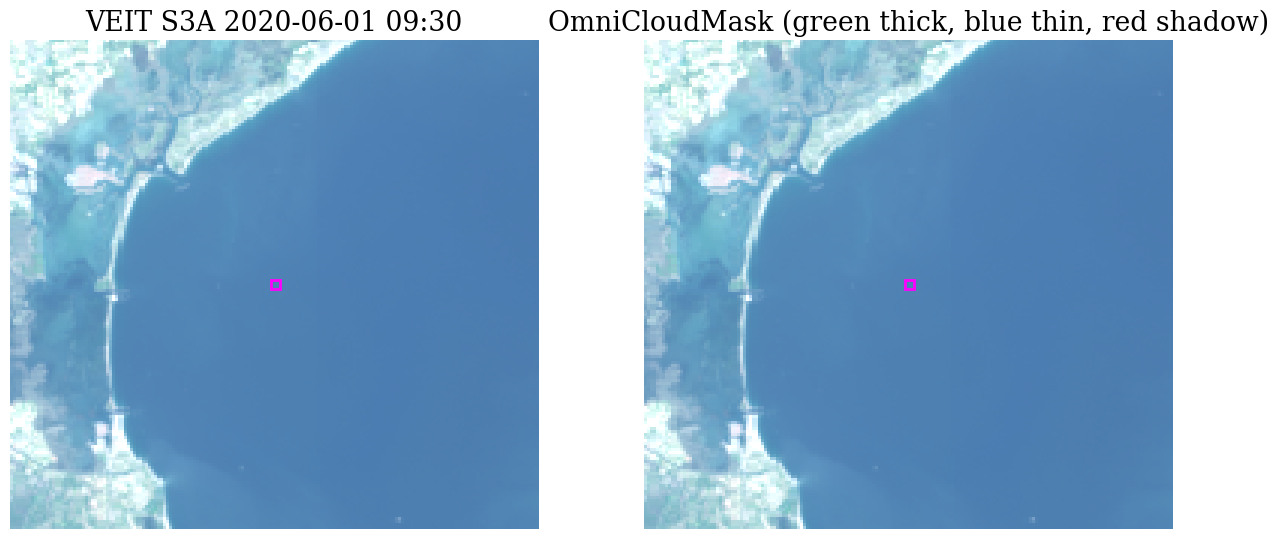

In [9]:
def quick_look(code, i=0):
    sat = satellite[code]
    t = sat.time.values[i]
    row = inventory[code][inventory[code].index <= pd.Timestamp(t)].iloc[-1]
    with xr.open_dataset(local_path(code, row)) as r:
        r = r.load()
    rgb = r.radiance.isel(bands=[OLCI_BANDS.index(b) for b in ('Oa08', 'Oa06', 'Oa04')]).transpose('rows', 'columns', 'bands')
    rgb = (rgb / rgb.quantile(0.98)).clip(0, 1) ** 0.6
    ocm = ocm_mask(r)
    o = olci[code].sel(time=t)
    h = SITES[code]['half_box']
    fig, axs = plt.subplots(1, 2, figsize=(15, 7))
    for ax in axs:
        ax.imshow(rgb.values)
        ax.add_patch(mpl.patches.Rectangle((int(o.ix) - h - 0.5, int(o.iy) - h - 0.5), 2 * h + 1, 2 * h + 1,
                                           fill=False, ec='magenta', lw=2))
        ax.set_axis_off()
    if ocm is not None:
        axs[1].imshow(ocm, cmap=mpl.colors.ListedColormap([(0, 0, 0, 0), 'green', 'blue', 'red']), vmin=0, vmax=3,
                      alpha=0.45)
    axs[0].set_title(f'{code} {str(sat.platform.values[i])} {pd.Timestamp(t):%Y-%m-%d %H:%M}')
    axs[1].set_title('OmniCloudMask (green thick, blue thin, red shadow)' if ocm is not None else 'no OmniCloudMask')
    plt.show()


quick_look(SITE_CODES[0])

## 7. Simulations with the current model

For each valid scene, the AERONET-OC measurements within $\pm\Delta t$ of the overpass are simulated at the
**exact geometry of the scene** ($\theta_0$, $\theta_v$, $\phi$ of the box; day of year of the overpass):

1. $R_{rs}$ of the AERONET-OC bands reconstructed at nadir from 350 to 1150 nm with `invRrs`
   (`radcalnet_oc.reconstruction.Reconstruction`), extended beyond with the pure-water model;
2. aerosol mixture retrieved from the spectral AOT (`radcalnet_oc.Aerosol`);
3. `Process(**MODEL).execute(sunglint=SUNGLINT)`: TOA reflectance `Rtoa`, direct sunglint `Rglint` and
   `Rtoa_glint`, glint angle, glint fraction at 865 nm and bitmask `glint_flags`, glint uncertainty `Rglint_unc`
   and spectral flag `glint_uncertain`;
4. uncertainty budget (`uncertainty_budget`, if `BUDGET`) of the measurement nearest to the overpass: inputs
   (AOT, water vapour, ozone, pressure, wind, $R_{rs}$) propagated by central differences through `Process`, the
   direct-glint uncertainty and the model gap per sunglint level and sun zenith class (table made from the
   Sentinel-2 matchups, viewing zenith < 12°: an extrapolation for the OLCI viewing angles), combined in
   quadrature; the relative terms are applied to all the measurements of the window;
5. band integration with the OLCI responses shifted to the $\lambda_0$ of the box (section 4): radiance
   $L^{b}_{sim}$, $E_0$-weighted band reflectance and band uncertainties.

The simulations are cached per scene in `ODIR/simulations/<code>/` with the provenance attributes of `Process`;
a scene already simulated with other settings is recomputed. Runtime: about 0.5-2 min per scene
(with the budget, most of it in the 12 perturbed runs), 0.6-1 GB per process.

In [10]:
INPUT_VARS = ['tcwv', 'tco3', 'tcno2', 'pressure', 'wind', 'aot550', 'aot865', 'ang_exp']
RECORD_VARS = INPUT_VARS + ['chl', 'level']
_RECONSTRUCTION = None


def _duplicate(ds):
    '''Process squeezes a time dimension of length 1: duplicate a single measurement (1 s later).'''
    if ds.sizes['time'] > 1:
        return ds, False
    return xr.concat([ds, ds.assign_coords(time=ds.time + np.timedelta64(1, 's'))], 'time'), True


def _run(ds, sza, vza, azi, doy):
    ds = ds.copy()
    ds['sza'] = xr.full_like(ds.aot550, sza)
    ds['day_of_year'] = xr.full_like(ds.aot550, doy, dtype=int)
    p = radoc.Process(ds, vza=xr.DataArray([vza], coords={'vza': [vza]}, dims='vza'),
                      azi=xr.DataArray([azi], coords={'azi': [azi]}, dims='azi'), **MODEL)
    aerosol = radoc.Aerosol(ds.naot.dropna('wl_aeronet', how='any'), p.lut.naot_lut)   # bands of all the measurements
    aerosol.process()
    p.execute(aerosol_combination=aerosol.model_db.aerosol_combination, sunglint=SUNGLINT)
    return p


def settings_match(attrs):
    '''Same settings and release (the git commit of a development install is not compared).'''
    release = lambda v: str(v).split('+')[0]
    return all((release(attrs.get(k)) == release(v)) if k == 'radcalnet_oc_version' else str(attrs.get(k)) == str(v)
               for k, v in SETTINGS.items())


def simulate_scene(code, sat, records):
    '''Simulated TOA radiance in the OLCI bands of the AERONET-OC measurements ``records`` at the geometry of ``sat``.'''
    t = pd.Timestamp(sat.time.values)
    cache = opj(ODIR, 'simulations', code, f'{code}_{str(sat.platform.values)}_{t:%Y%m%dT%H%M%S}.nc')
    if os.path.exists(cache):
        with xr.open_dataset(cache) as c:
            if settings_match(c.attrs):
                return c.load()
    global _RECONSTRUCTION
    logging.getLogger('radcalnet_oc').setLevel(logging.ERROR)
    warnings.simplefilter('ignore')
    if _RECONSTRUCTION is None:
        _RECONSTRUCTION = Reconstruction()
    # measurements with at least 5 valid Rrs bands; missing chlorophyll first guess: 1 mg m-3
    records = records.isel(time=np.flatnonzero((np.isfinite(records.Rrs_Lwn) & (records.Rrs_Lwn > -1)).sum('wl').values >= 5))
    if records.sizes['time'] == 0:
        return None
    chl = records.chl.where(np.isfinite(records.chl) & (records.chl > 0), 1.)
    try:
        hyp = _RECONSTRUCTION.reconstruct(records.Rrs_Lwn, records.sza_aeronet, chl=chl)
    except ValueError:      # a fit that cannot start: reconstruct the measurements one by one
        parts = []
        for i in range(records.sizes['time']):
            try:
                parts.append(_RECONSTRUCTION.reconstruct(records.Rrs_Lwn.isel(time=[i]), records.sza_aeronet.isel(time=[i]),
                                                         chl=chl.isel(time=[i])))
            except ValueError:
                pass
        if not parts:
            return None
        hyp = xr.concat(parts, 'time')
    hyp = hyp.where(hyp.success, drop=True)
    if hyp.sizes['time'] == 0:
        return None
    ds = records.sel(time=hyp.time)[INPUT_VARS + ['naot']].copy()
    ds['Rrs'] = hyp.Rrs_nadir
    ds, single = _duplicate(ds)
    sza, vza, azi, doy = float(sat.sza), float(sat.vza), float(sat.azi), t.dayofyear
    p = _run(ds, sza, vza, azi, doy)
    db = p.radcalnet_db.sel(wl=slice(370, 1060))
    if single:
        db = db.isel(time=[0])
    wl = db.wl.values
    S = srf_matrix(wl, sat.lambda0.values)
    E0 = db.E0.transpose('time', 'wl').values
    R = db.Rtoa_glint.transpose('time', 'wl').values
    Rg = db.Rglint.transpose('time', 'wl').values
    Rg_unc = db.Rglint_unc.transpose('time', 'wl').values
    sims = hyp.time.values
    out = xr.Dataset(coords={'sim': sims, 'band': OLCI_BANDS})
    out['Lsim'] = (('sim', 'band'), band_average(R * E0, wl, S) / np.pi)
    out['Lglint'] = (('sim', 'band'), band_average(Rg * E0, wl, S) / np.pi)
    out['Rsim'] = (('sim', 'band'), band_average(R, wl, S, E0))
    out['E0_band'] = (('sim', 'band'), band_average(E0, wl, S))
    out['glint_unc_rel'] = (('sim', 'band'), band_average(Rg_unc, wl, S, E0) / band_average(R, wl, S, E0))
    for v in ['glint_flags', 'glint_fraction', 'glint_angle', 'Rg_surface']:
        out[v] = ('sim', np.atleast_1d(db[v].values)[:len(sims)])
    for v in RECORD_VARS:
        out[v] = ('sim', records[v].sel(time=sims).values)
    out['rrs_rmsd'] = ('sim', hyp.rmsd.values)
    out['dt_min'] = ('sim', (sims - sat.time.values) / np.timedelta64(1, 'm'))
    out['Ltoa_spectrum'] = ('wl_spectrum', (np.median(R * E0, axis=0) / np.pi)[::10].astype('float32'))
    out = out.assign_coords(wl_spectrum=wl[::10])

    if BUDGET:   # budget of the measurement nearest to the overpass
        k = int(np.argmin(np.abs(out.dt_min.values)))
        dk, _ = _duplicate(ds.isel(time=[k]))
        pk = _run(dk, sza, vza, azi, doy)
        bk = uncertainty_budget(pk, inputs=BUDGET_INPUTS).sel(wl=slice(370, 1060)).isel(time=0)
        Rk, E0k = bk.Rtoa_glint.values, bk.E0.values
        terms = [v for v in bk.data_vars if v.startswith('u_') and v not in ('u_total', 'u_total_rel')]
        for v in terms + ['u_total']:
            out[f'{v}_rel'] = ('band', band_average(bk[v].values, wl, S, E0k) / band_average(Rk, wl, S, E0k))
        out.attrs['budget_measurement'] = str(out.sim.values[k])
    out.attrs.update({k: str(v) for k, v in SETTINGS.items()})
    out.attrs.update({'site': code, 'scene_time': str(sat.time.values), 'sza': sza, 'vza': vza, 'azi': azi,
                      'platform': str(sat.platform.values)})
    os.makedirs(os.path.dirname(cache), exist_ok=True)
    out.to_netcdf(cache)
    return out

In [11]:
def simulate_safe(code, sat, records):
    '''simulate_scene, with the error message instead of an exception (one failed scene does not stop the run).'''
    try:
        return simulate_scene(code, sat, records)
    except Exception as e:
        return f'{type(e).__name__}: {e}'


simulations = {}
for code in SITE_CODES:
    if code not in satellite:
        continue
    sat, a = satellite[code], aeronet[code]
    jobs = []
    for t in sat.time.values:
        rec = a.sel(time=slice(t - DELTA_TIME, t + DELTA_TIME))
        if rec.sizes['time']:
            jobs.append((t, rec))
    res = Parallel(n_jobs=N_JOBS)(delayed(simulate_safe)(code, sat.sel(time=t), rec) for t, rec in jobs)
    for (t, _), r in zip(jobs, res):
        if isinstance(r, str):
            print(f'{code} {pd.Timestamp(t):%Y-%m-%d %H:%M}: simulation failed ({r})')
    res = [None if isinstance(r, str) else r for r in res]
    simulations[code] = {t: s for (t, _), s in zip(jobs, res) if s is not None}
    print(f'{code}: {len(simulations[code])} scenes simulated out of {len(jobs)} with AERONET-OC within +/- {DELTA_TIME}')
first = next(iter(next(iter(simulations.values())).values()))
pd.Series({k: first.attrs.get(k) for k in ['radcalnet_oc_version', 'o2_model', 'gas_coupling', 'gas_coupling_table',
                                            'rrs_extension', 'rayleigh_pressure', 'solar_database', 'toa_lut',
                                            'toa_lut_doi', 'sunglint_stats']}, name='settings of the simulations').to_frame()

VEIT: 44 scenes simulated out of 44 with AERONET-OC within +/- 60 minutes


,settings of the simulations
radcalnet_oc_version,1.2.0+g5055a72
o2_model,lbl
gas_coupling,path_length
gas_coupling_table,gas_coupling_ppld.csv
rrs_extension,pure_water
rayleigh_pressure,1
solar_database,tsis
toa_lut,toa_lut_opac_wind_v3.nc
toa_lut_doi,10.5281/zenodo.23394202
sunglint_stats,cm_iso_mix


## 8. Matchup dataset

For each scene: the median of the simulations of the window, $\tilde L_{sim}$, and the ratio
$r_b = L^{b}_{OLCI} / \tilde L^{b}_{sim}$. Its relative standard uncertainty combines, as independent terms,

$$
u^2(r_b)/r_b^2 = \underbrace{u^2_{sim}}_{\text{budget}} + \underbrace{u^2_{OLCI}}_{\texttt{radiance\_unc}}
+ \underbrace{(\sigma_{box}/L_{OLCI})^2}_{\text{spatial}} + \underbrace{(\sigma_{sim}/\tilde L_{sim})^2}_{\text{temporal}} ,
$$

with $u_{sim}$ the total of the budget (inputs, glint, model gap), $\sigma_{box}$ the standard deviation of the box
and $\sigma_{sim}$ that of the simulations of the window. The normalised deviation $z_b = (r_b - 1)/u(r_b)$ tells
whether a matchup is consistent with its uncertainty ($|z| < 2$ at $k = 2$). The glint flags of a scene are the
bitwise OR of those of its measurements (conservative), and a band is `glint_uncertain` when the band-integrated
glint uncertainty exceeds 5 % of the simulated signal.

In [12]:
GLINT_UNC_THRESHOLD = coxmunk.GLINT_UNC_THRESHOLD


def subset(m, mask):
    '''Matchups where ``mask`` (time) is true.'''
    return m.isel(time=np.flatnonzero(np.asarray(mask)))


def matchup_dataset(code):
    sat, sims = satellite[code], simulations.get(code, {})
    rows = []
    for t, s in sims.items():
        x = xr.Dataset({'Lsim': s.Lsim.median('sim'), 'Lsim_std': s.Lsim.std('sim'),
                        'Lglint': s.Lglint.median('sim'), 'Rsim': s.Rsim.median('sim'),
                        'E0_band': s.E0_band.median('sim'), 'glint_unc_rel': s.glint_unc_rel.median('sim'),
                        'n_sim': s.sizes['sim'],
                        'glint_flags': np.bitwise_or.reduce(s.glint_flags.values.astype(int)),
                        'glint_fraction': s.glint_fraction.median(), 'glint_angle': s.glint_angle.median(),
                        'aot550': s.aot550.median(), 'ang_exp': s.ang_exp.median(), 'wind': s.wind.median(),
                        'tcwv': s.tcwv.median(), 'chl': s.chl.median(), 'level': s.level.min(),
                        'rrs_rmsd': s.rrs_rmsd.median(),
                        'dt_min': float(s.dt_min.values[np.abs(s.dt_min.values).argmin()])})
        for v in s.data_vars:
            if v.startswith('u_'):
                x[v] = s[v]
        rows.append(x.expand_dims(time=[t]))
    if not rows:
        return None
    m = xr.merge([sat, xr.concat(rows, 'time')], join='inner')
    m['site'] = ('time', [code] * m.sizes['time'])
    m['ratio'] = m.L_olci / m.Lsim
    m['ratio_nocentre'] = m.L_olci_nocentre / m.Lsim
    # ratio of reflectances with the OLCI solar flux (section 2): r * E0_sim / (mu0 F_OLCI)
    m['ratio_refl'] = m.ratio * m.E0_band / (np.cos(np.radians(m.sza)) * m.solar_flux)
    u_sim = m.u_total_rel if 'u_total_rel' in m else xr.full_like(m.ratio, np.nan)
    m['u_sim_rel'] = u_sim
    m['u_ratio_rel'] = np.sqrt(u_sim.fillna(0) ** 2 + m.u_olci_rel ** 2 + (m.L_olci_std / m.L_olci) ** 2
                               + (m.Lsim_std.fillna(0) / m.Lsim) ** 2)
    m['z'] = (m.ratio - 1) / (m.ratio * m.u_ratio_rel)
    m['glint_uncertain'] = (m.glint_unc_rel > GLINT_UNC_THRESHOLD).astype(int)
    m['glint_level'] = ('time', radoc.uncertainty.glint_level(m.glint_flags.values))
    return m


matchups = {code: matchup_dataset(code) for code in SITE_CODES if code in satellite}
matchups = {k: v for k, v in matchups.items() if v is not None}
mu = xr.concat(list(matchups.values()), 'time').sortby('time')
WINDOW_BANDS = ['Oa01', 'Oa02', 'Oa03', 'Oa04', 'Oa05', 'Oa06', 'Oa07', 'Oa08', 'Oa09', 'Oa10', 'Oa12', 'Oa16',
                'Oa17', 'Oa18', 'Oa21']
ABSORPTION_BANDS = ['Oa11', 'Oa13', 'Oa14', 'Oa15', 'Oa19', 'Oa20']
print(f'{mu.sizes["time"]} matchups: ' + ', '.join(f'{s} {p}: {int(((mu.site == s) & (mu.platform == p)).sum())}'
                                                   for s in matchups for p in PLATFORMS))
pd.Series(mu.glint_level.values).value_counts().rename('matchups per glint level').to_frame().T

44 matchups: VEIT S3A: 24, VEIT S3B: 20


,low,none,near_specular,moderate
matchups per glint level,20,11,10,3


## 9. Monitoring

### 9.1 Example of matchup

Simulated spectrum (median of the window, with the direct sunglint, 1 nm sampling), simulated band radiance with the
$k = 2$ uncertainty of the budget, and OLCI radiance (median, range of the box).

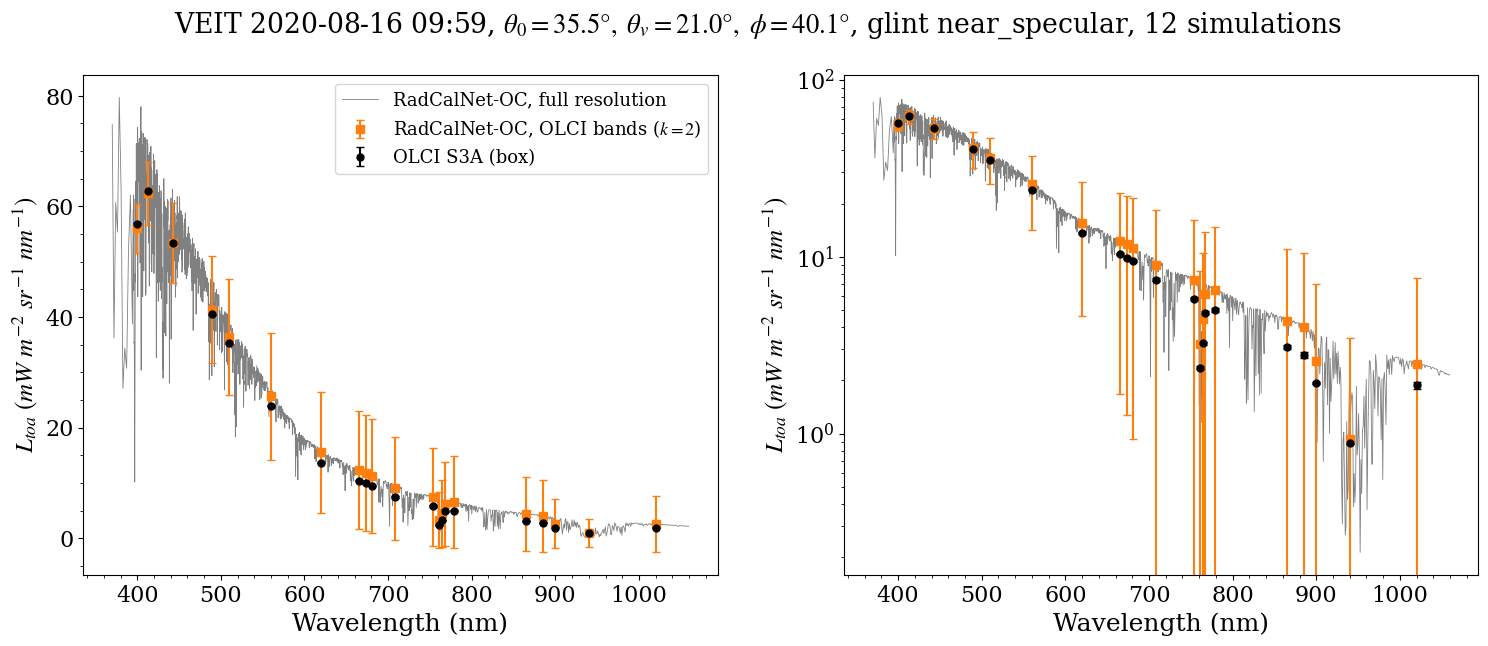

In [13]:
def plot_example(m, sims, i):
    x = m.isel(time=i)
    t = x.time.values
    s = sims[str(x.site.values)][t]
    wl = np.array([NOMINAL_WL[b] for b in OLCI_BANDS])
    fig, axs = plt.subplots(1, 2, figsize=(18, 6.5))
    for ax in axs:
        ax.plot(s.wl_spectrum, s.Ltoa_spectrum, color='grey', lw=0.6, label='RadCalNet-OC, full resolution')
        ax.errorbar(wl, x.Lsim, yerr=2 * x.Lsim * x.u_sim_rel.fillna(0), fmt='s', color='tab:orange', ms=6, capsize=3,
                    label='RadCalNet-OC, OLCI bands ($k=2$)')
        ax.errorbar(wl, x.L_olci, yerr=x.L_olci_std, fmt='o', color='k', ms=5, capsize=3,
                    label=f'OLCI {str(x.platform.values)} (box)')
        ax.set_xlabel('Wavelength (nm)')
        ax.set_ylabel(r'$L_{toa}\ (mW\ m^{-2}\ sr^{-1}\ nm^{-1})$')
        ax.minorticks_on()
    axs[1].semilogy()
    axs[0].legend(fontsize=13)
    fig.suptitle(f'{str(x.site.values)} {pd.Timestamp(t):%Y-%m-%d %H:%M}, '
                 + r'$\theta_0=%.1f°,\ \theta_v=%.1f°,\ \phi=%.1f°$, glint %s, %i simulations'
                 % (x.sza, x.vza, x.azi, str(x.glint_level.values), x.n_sim))
    plt.show()


plot_example(mu, simulations, int(np.argmax(mu.n_sim.values)))

### 9.2 Time series of the ratio with the simulation uncertainty

Per site and band: ratio $r_b$ of each matchup (colour: platform; open symbols: moderate or stronger glint), with
the shaded bands $1 \pm u_{sim}$ ($k = 1$) and $1 \pm 2u_{sim}$ ($k = 2$) from the median budget of the
matchups, and the running median over 90 days.

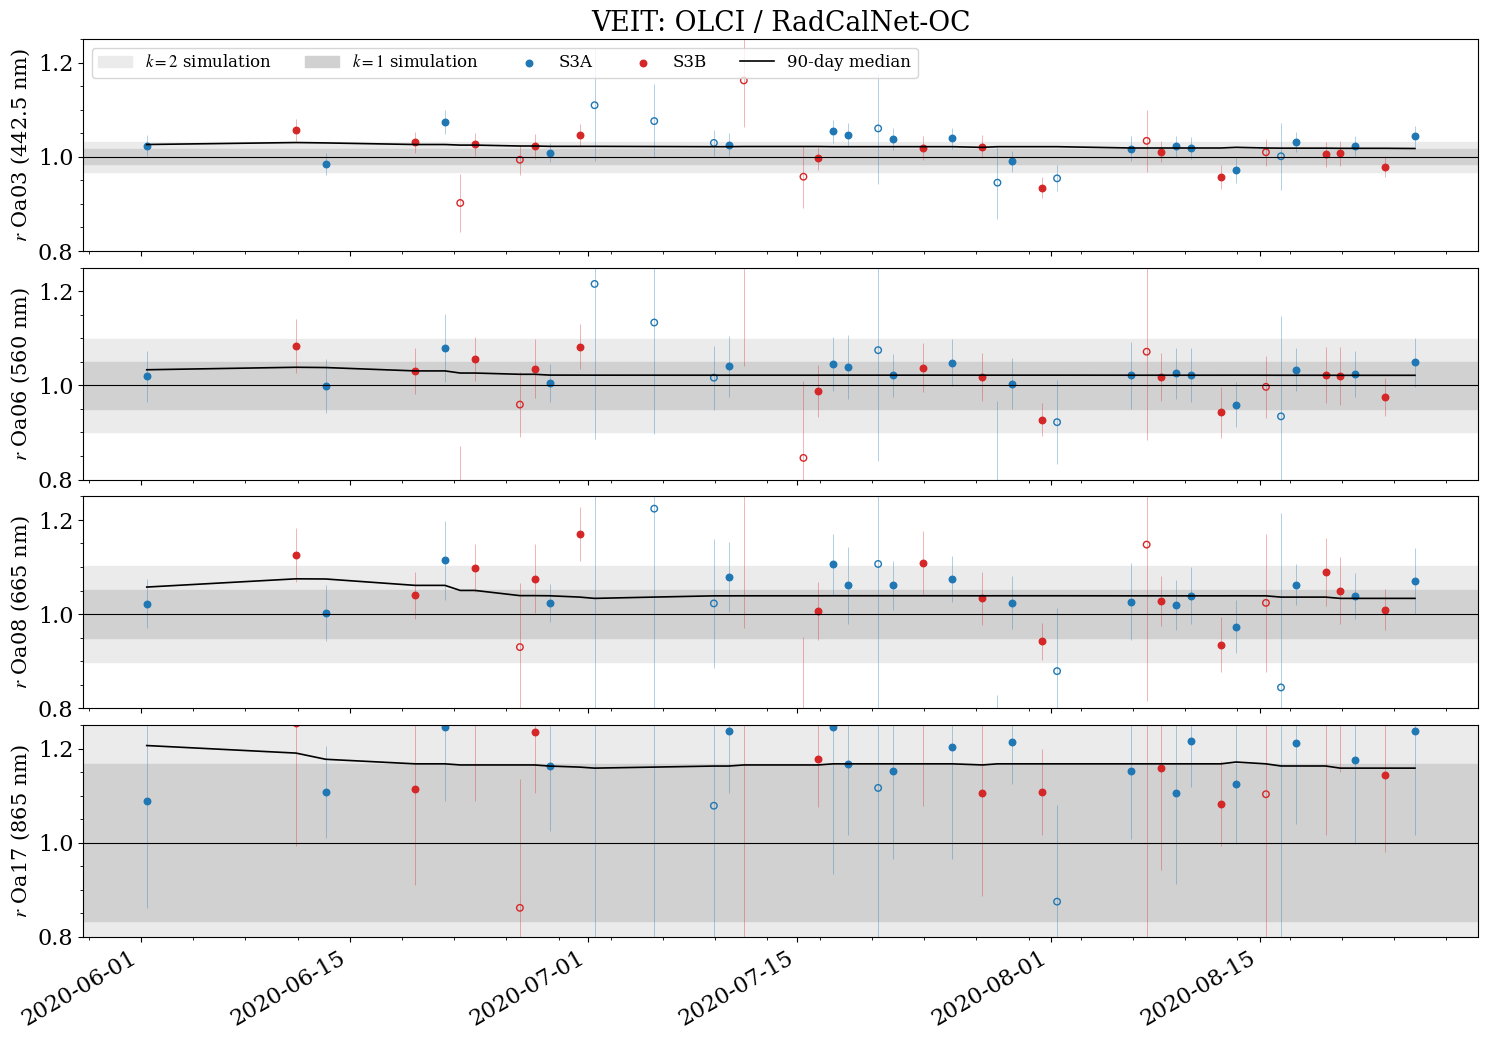

In [14]:
TS_BANDS = ['Oa03', 'Oa06', 'Oa08', 'Oa17']


def plot_timeseries(m, bands=TS_BANDS):
    for code in np.unique(m.site.values):
        ms = subset(m, m.site == code)
        fig, axs = plt.subplots(len(bands), 1, figsize=(18, 3.3 * len(bands)), sharex=True)
        fig.subplots_adjust(hspace=0.08)
        for ax, b in zip(np.atleast_1d(axs), bands):
            x = ms.sel(band=b)
            u = float(x.u_sim_rel.median())
            if np.isfinite(u):
                ax.axhspan(1 - 2 * u, 1 + 2 * u, color='0.92', zorder=-2, label='$k=2$ simulation')
                ax.axhspan(1 - u, 1 + u, color='0.82', zorder=-1, label='$k=1$ simulation')
            for p, c in PLATFORMS.items():
                xp = subset(x, x.platform == p)
                if not xp.sizes['time']:
                    continue
                glint = (xp.glint_flags.astype(int) & radoc.GLINT_FLAGS['glint_moderate']) > 0
                ax.errorbar(xp.time.values, xp.ratio, yerr=xp.ratio * xp.u_ratio_rel, fmt='none', ecolor=c,
                            elinewidth=0.6, alpha=0.4)
                ax.scatter(xp.time.values[~glint.values], xp.ratio.values[~glint.values], color=c, s=22, label=p)
                ax.scatter(xp.time.values[glint.values], xp.ratio.values[glint.values], facecolor='none',
                           edgecolor=c, s=22)
            r = x.ratio.to_series().sort_index()
            if len(r) > 5:
                r.rolling('90D', min_periods=3, center=True).median().plot(ax=ax, color='k', lw=1.2, label='90-day median')
            ax.axhline(1, color='k', lw=0.8)
            ax.set_ylabel(r'$r$ ' + f'{b} ({NOMINAL_WL[b]:g} nm)', fontsize=15)
            ax.set_ylim(0.8, 1.25)
            ax.minorticks_on()
        np.atleast_1d(axs)[0].legend(ncol=5, fontsize=12, loc='upper left')
        np.atleast_1d(axs)[0].set_title(f'{code}: OLCI / RadCalNet-OC')
        np.atleast_1d(axs)[-1].set_xlabel('')
        plt.show()


plot_timeseries(mu)

### 9.3 Per-band summary

Robust statistics of $r_b$ per site and platform: median, robust standard deviation
$s = 1.4826\,\mathrm{MAD}$, standard error of the median $1.2533\,s/\sqrt{N}$, median $u_{sim}$ and median
$u(r_b)$ ($k = 1$), and the fraction of matchups with $|z| < 2$. A median ratio departing from 1 by more than its
standard error *and* more than $u_{sim}$ points either to OLCI or to a systematic error of the simulation: the
monitoring flags it; it does not attribute it.

In [15]:
def robust(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if not len(x):
        return np.nan, np.nan, 0
    med = np.median(x)
    return med, 1.4826 * np.median(np.abs(x - med)), len(x)


def summary_table(m, groups=('site', 'platform'), bands=OLCI_BANDS, var='ratio'):
    rows = []
    keys = [np.unique(m[g].values) for g in groups]
    for key in pd.MultiIndex.from_product(keys):
        sel = np.ones(m.sizes['time'], bool)
        for g, k in zip(groups, key):
            sel &= m[g].values == k
        if not sel.any():
            continue
        ms = m.isel(time=np.flatnonzero(sel))
        for b in bands:
            x = ms.sel(band=b)
            med, s, n = robust(x[var].values)
            rows.append({**dict(zip(groups, key)), 'band': b, 'wl': NOMINAL_WL[b], 'N': n, 'median': med,
                         'rsd_%': 100 * s, 'se_%': 100 * 1.2533 * s / np.sqrt(max(n, 1)),
                         'u_sim_%': 100 * float(x.u_sim_rel.median()), 'u_ratio_%': 100 * float(x.u_ratio_rel.median()),
                         'frac_|z|<2': float((np.abs(x.z) < 2).mean())})
    return pd.DataFrame(rows)


summary = summary_table(mu)
summary.pivot_table(index=['band', 'wl'], columns=['site', 'platform'], values=['median', 'rsd_%', 'u_sim_%']).round(3)

median          rsd_%         u_sim_%        
site               VEIT           VEIT            VEIT        
platform            S3A    S3B     S3A     S3B     S3A     S3B
band wl                                                       
Oa01 400.000000   1.026  1.015   2.047   2.115   1.239   1.054
Oa02 412.500000   1.025  1.008   2.532   1.937   1.340   1.144
Oa03 442.500000   1.025  1.010   2.906   2.770   1.669   1.436
Oa04 490.000000   1.028  1.017   3.576   4.368   2.688   2.336
Oa05 510.000000   1.026  1.018   3.735   4.690   3.280   2.913
Oa06 560.000000   1.023  1.019   3.122   5.946   5.107   4.789
Oa07 620.000000   1.028  1.023   4.414   8.003   5.520   4.882
Oa08 665.000000   1.039  1.036   5.002  10.026   5.285   4.637
Oa09 673.799988   1.042  1.046   5.116  10.832   5.433   4.774
Oa10 681.200012   1.050  1.054   5.112  10.991   5.598   5.021
Oa11 708.799988   1.089  1.069   5.177  13.382   6.811   6.244
Oa12 753.799988   1.105  1.093   6.664  14.280   8.256   7.550
Oa13 761.200012   0.941  0.958   7.271   8.402  15.956  14.465
Oa14 764.400024   0.991  1.008   6.103  13.420  12.072  11.605
Oa15 767.500000   1.111  1.105   7.176  13.048   9.365   8.925
Oa16 778.799988   1.119  1.104   7.644  13.441   9.265   9.074
Oa17 865.000000   1.165  1.168   8.792  13.811  15.397  17.943
Oa18 885.000000   1.180  1.189   9.647  14.127  16.573  19.289
Oa19 900.000000   1.220  1.212   9.286  13.619  21.912  24.992
Oa20 940.000000   1.257  1.211  12.424  16.557  41.951  45.803
Oa21 1020.000000  1.421  1.407  15.422  23.253  22.054  26.403

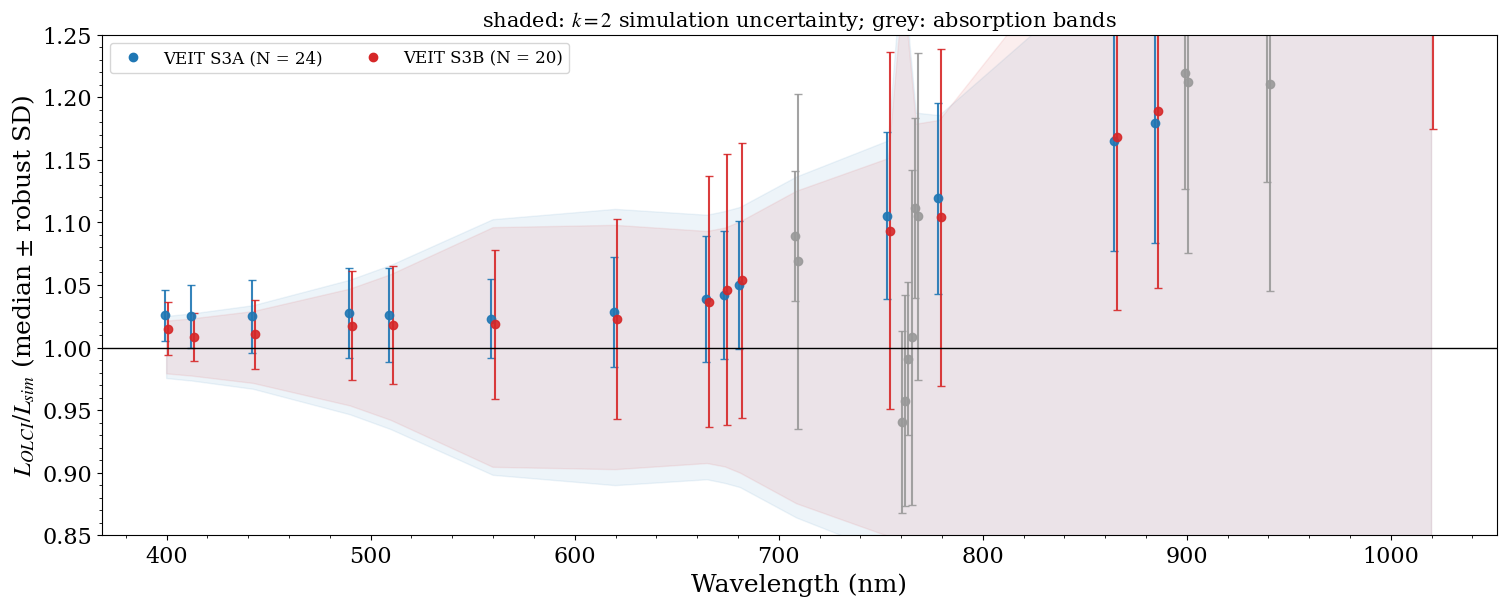

In [16]:
def plot_ratio_spectrum(tab, title=''):
    fig, ax = plt.subplots(figsize=(18, 6.5))
    groups = list(tab.groupby(['site', 'platform']))
    for j, ((site, p), g) in enumerate(groups):
        dx = (j - (len(groups) - 1) / 2) * 1.6
        c = PLATFORMS.get(p, 'k')
        mk = {'VEIT': 'o', 'GABU': 's', 'CORO': 'D'}.get(site, 'o')
        for _, r in g.iterrows():
            col = '0.6' if r.band in ABSORPTION_BANDS else c
            ax.errorbar(r.wl + dx, r['median'], yerr=r['rsd_%'] / 100, fmt=mk, color=col, ms=6, capsize=3, alpha=0.9)
        ax.plot([], [], mk, color=c, label=f'{site} {p} (N = {int(g.N.max())})')
        g = g.sort_values('wl')
        ax.fill_between(g.wl, 1 - 2 * g['u_sim_%'] / 100, 1 + 2 * g['u_sim_%'] / 100, color=c, alpha=0.08)
    ax.axhline(1, color='k', lw=1)
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel(r'$L_{OLCI}/L_{sim}$ (median $\pm$ robust SD)')
    ax.set_title(title + 'shaded: $k=2$ simulation uncertainty; grey: absorption bands', fontsize=15)
    ax.set_ylim(0.85, 1.25)
    ax.legend(fontsize=12, ncol=3)
    ax.minorticks_on()
    plt.show()


plot_ratio_spectrum(summary)

### 9.4 Drift

Trend of $r_b$ per site, platform and band, from the Theil-Sen estimator (robust to the outliers) on the decimal
year, with its 95 % confidence interval, in % per year relative to the median ratio. Computed when the series spans
at least one year with at least 10 matchups; the seasonal cycle of the geometry and of the glint is not removed, so
a trend must be read with the trend of the glint fraction and of $\theta_0$ printed in the same table.

In [17]:
def decimal_year(t):
    t = pd.DatetimeIndex(t)
    return t.year + (t.dayofyear - 1) / 365.25


def drift_table(m, bands=OLCI_BANDS, min_n=10, min_span=1.):
    rows = []
    for (site, p), idx in pd.DataFrame({'s': m.site.values, 'p': m.platform.values}).groupby(['s', 'p']).groups.items():
        ms = m.isel(time=np.asarray(idx))
        yr = decimal_year(ms.time.values)
        if len(yr) < min_n or np.ptp(yr) < min_span:
            rows.append({'site': site, 'platform': p, 'band': 'all', 'N': len(yr),
                         'note': f'span {np.ptp(yr):.2f} yr < {min_span} or N < {min_n}: no trend'})
            continue
        for b in bands:
            y = ms.ratio.sel(band=b).values
            ok = np.isfinite(y)
            slope, _, lo, hi = scipy.stats.theilslopes(y[ok], yr[ok], alpha=0.95)
            med = np.median(y[ok])
            rows.append({'site': site, 'platform': p, 'band': b, 'N': int(ok.sum()), 'span_yr': np.ptp(yr[ok]),
                         'drift_%/yr': 100 * slope / med, 'ci_lo': 100 * lo / med, 'ci_hi': 100 * hi / med,
                         'significant': not (lo <= 0 <= hi)})
    return pd.DataFrame(rows)


drift = drift_table(mu)
drift.round(3)

,site,platform,band,N,note
0,VEIT,S3A,all,24,span 0.23 yr < 1.0 or N < 10: no trend
1,VEIT,S3B,all,20,span 0.20 yr < 1.0 or N < 10: no trend


### 9.5 S3A / S3B inter-consistency

Difference of the median ratios S3A - S3B per site and band with a bootstrap 95 % interval (resampling of the
matchups of each platform). The simulation is the same for both platforms, so this difference is free of the
systematic errors of the model shared by the two platforms; it keeps the differences of geometry (orbits) and of
season sampling.

In [18]:
def platform_consistency(m, bands=OLCI_BANDS, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for site in np.unique(m.site.values):
        ms = subset(m, m.site == site)
        a = subset(ms, ms.platform == 'S3A')
        b_ = subset(ms, ms.platform == 'S3B')
        if a.sizes['time'] < 3 or b_.sizes['time'] < 3:
            rows.append({'site': site, 'band': 'all', 'N_S3A': a.sizes['time'], 'N_S3B': b_.sizes['time'],
                         'note': 'fewer than 3 matchups for a platform'})
            continue
        for b in bands:
            xa, xb = a.ratio.sel(band=b).values, b_.ratio.sel(band=b).values
            xa, xb = xa[np.isfinite(xa)], xb[np.isfinite(xb)]
            d = np.median(xa) - np.median(xb)
            boot = [np.median(rng.choice(xa, len(xa))) - np.median(rng.choice(xb, len(xb))) for _ in range(n_boot)]
            rows.append({'site': site, 'band': b, 'N_S3A': len(xa), 'N_S3B': len(xb), 'S3A-S3B_%': 100 * d,
                         'ci_lo_%': 100 * np.percentile(boot, 2.5), 'ci_hi_%': 100 * np.percentile(boot, 97.5)})
    return pd.DataFrame(rows)


consistency = platform_consistency(mu)
consistency.round(3)

,site,band,N_S3A,N_S3B,S3A-S3B_%,ci_lo_%,ci_hi_%
0,VEIT,Oa01,24,20,1.073,-0.240,2.682
1,VEIT,Oa02,24,20,1.658,0.202,3.110
2,VEIT,Oa03,24,20,1.441,-0.373,3.514
3,VEIT,Oa04,24,20,1.010,-1.204,4.273
4,VEIT,Oa05,24,20,0.784,-1.044,4.396
5,VEIT,Oa06,24,20,0.453,-1.515,4.376
6,VEIT,Oa07,24,20,0.549,-3.840,5.375
7,VEIT,Oa08,24,20,0.237,-5.826,4.644
8,VEIT,Oa09,24,20,-0.401,-6.921,5.001
9,VEIT,Oa10,24,20,-0.387,-6.986,4.436


### 9.6 Summary table

One row per site, platform and band: matchups, median ratio and its standard error, robust SD, simulation
uncertainty, consistency fraction and drift. This is the table of the monitoring report.

In [19]:
monitoring = summary.merge(drift[drift.band != 'all'][['site', 'platform', 'band', 'drift_%/yr', 'ci_lo', 'ci_hi']]
                           if 'drift_%/yr' in drift else pd.DataFrame(columns=['site', 'platform', 'band']),
                           on=['site', 'platform', 'band'], how='left')
monitoring['flag'] = np.where(np.abs(monitoring['median'] - 1) * 100 > np.maximum(2 * monitoring['se_%'],
                                                                                   monitoring['u_sim_%']),
                              'ratio outside u_sim', '')
monitoring[monitoring.band.isin(WINDOW_BANDS)].set_index(['site', 'platform', 'band']).round(3)

wl   N  median   rsd_%   se_%  u_sim_%  \
site platform band                                                    
VEIT S3A      Oa01   400.000000  24   1.026   2.047  0.524    1.239   
              Oa02   412.500000  24   1.025   2.532  0.648    1.340   
              Oa03   442.500000  24   1.025   2.906  0.744    1.669   
              Oa04   490.000000  24   1.028   3.576  0.915    2.688   
              Oa05   510.000000  24   1.026   3.735  0.956    3.280   
              Oa06   560.000000  24   1.023   3.122  0.799    5.107   
              Oa07   620.000000  24   1.028   4.414  1.129    5.520   
              Oa08   665.000000  24   1.039   5.002  1.280    5.285   
              Oa09   673.799988  24   1.042   5.116  1.309    5.433   
              Oa10   681.200012  24   1.050   5.112  1.308    5.598   
              Oa12   753.799988  24   1.105   6.664  1.705    8.256   
              Oa16   778.799988  24   1.119   7.644  1.956    9.265   
              Oa17   865.000000  24   1.165   8.792  2.249   15.397   
              Oa18   885.000000  24   1.180   9.647  2.468   16.573   
              Oa21  1020.000000  24   1.421  15.422  3.945   22.054   
     S3B      Oa01   400.000000  20   1.015   2.115  0.593    1.054   
              Oa02   412.500000  20   1.008   1.937  0.543    1.144   
              Oa03   442.500000  20   1.010   2.770  0.776    1.436   
              Oa04   490.000000  20   1.017   4.368  1.224    2.336   
              Oa05   510.000000  20   1.018   4.690  1.314    2.913   
              Oa06   560.000000  20   1.019   5.946  1.666    4.789   
              Oa07   620.000000  20   1.023   8.003  2.243    4.882   
              Oa08   665.000000  20   1.036  10.026  2.810    4.637   
              Oa09   673.799988  20   1.046  10.832  3.036    4.774   
              Oa10   681.200012  20   1.054  10.991  3.080    5.021   
              Oa12   753.799988  20   1.093  14.280  4.002    7.550   
              Oa16   778.799988  20   1.104  13.441  3.767    9.074   
              Oa17   865.000000  20   1.168  13.811  3.871   17.943   
              Oa18   885.000000  20   1.189  14.127  3.959   19.289   
              Oa21  1020.000000  20   1.407  23.253  6.516   26.403   

                    u_ratio_%  frac_|z|<2                 flag  
site platform band                                              
VEIT S3A      Oa01      2.056       0.917  ratio outside u_sim  
              Oa02      2.104       0.917  ratio outside u_sim  
              Oa03      2.390       0.917  ratio outside u_sim  
              Oa04      3.477       0.958  ratio outside u_sim  
              Oa05      3.884       1.000                       
              Oa06      5.671       1.000                       
              Oa07      6.213       1.000                       
              Oa08      6.293       1.000                       
              Oa09      6.875       1.000                       
              Oa10      6.849       1.000                       
              Oa12      9.715       0.958  ratio outside u_sim  
              Oa16     10.155       0.958  ratio outside u_sim  
              Oa17     16.793       0.875  ratio outside u_sim  
              Oa18     19.312       0.917  ratio outside u_sim  
              Oa21     32.724       0.958  ratio outside u_sim  
     S3B      Oa01      2.199       0.850  ratio outside u_sim  
              Oa02      2.142       0.850                       
              Oa03      2.528       0.900                       
              Oa04      3.360       0.850                       
              Oa05      3.994       0.900                       
              Oa06      5.696       0.950                       
              Oa07      6.457       0.900                       
              Oa08      6.165       0.850                       
              Oa09      6.418       0.800                       
              Oa10      6.474       0.800                       
 

## 10. Absorption-band diagnostics

The absorption bands are compared through their relative band depth, the ratio in the absorption band divided by
the ratio in a neighbouring window band,

$$
\delta_b = \frac{r_b}{r_{ref}},
$$

which removes most of the aerosol, surface and calibration differences ($\delta_b = 1$ for a perfect absorption
model). Pairs: Oa11/Oa10 (H$_2$O, 709 nm), Oa13, Oa14, Oa15/Oa12 (O$_2$-A, 761-768 nm), Oa19/Oa18 (H$_2$O,
900 nm), Oa20/Oa18 (H$_2$O, 940 nm). The O$_2$-B band (687 nm) has no dedicated OLCI band: Oa10 (681 nm) and Oa11
(709 nm) are on its edges. The depth depends on the shape of the response in these narrow features, assumed
for S3B to be that of S3A (section 4), and on the O$_2$-A coupling, an open question of the project
(EnMAP closure against CKD/PRISMA, ROADMAP task 26): the dependence on the air mass and on the water vapour column
is shown.

In [20]:
PAIRS = {'Oa11': 'Oa10', 'Oa13': 'Oa12', 'Oa14': 'Oa12', 'Oa15': 'Oa12', 'Oa19': 'Oa18', 'Oa20': 'Oa18'}
GAS = {'Oa11': 'H2O', 'Oa13': 'O2-A head', 'Oa14': 'O2-A', 'Oa15': 'O2-A wing', 'Oa19': 'H2O', 'Oa20': 'H2O 940'}


def band_depth(m):
    return xr.concat([(m.ratio.sel(band=b) / m.ratio.sel(band=r)).assign_coords(pair=f'{b}/{r}')
                      for b, r in PAIRS.items()], 'pair')


depth = band_depth(mu)
rows = []
for (site, p), idx in pd.DataFrame({'s': mu.site.values, 'p': mu.platform.values}).groupby(['s', 'p']).groups.items():
    for pair in depth.pair.values:
        med, s, n = robust(depth.sel(pair=pair).isel(time=np.asarray(idx)).values)
        rows.append({'site': site, 'platform': p, 'pair': pair, 'gas': GAS[pair.split('/')[0]], 'N': n,
                     'median': med, 'rsd': s})
pd.DataFrame(rows).pivot_table(index=['pair', 'gas'], columns=['site', 'platform'], values='median').round(3)

site                  VEIT       
platform               S3A    S3B
pair      gas                    
Oa11/Oa10 H2O        1.018  1.019
Oa13/Oa12 O2-A head  0.853  0.863
Oa14/Oa12 O2-A       0.910  0.913
Oa15/Oa12 O2-A wing  1.001  1.003
Oa19/Oa18 H2O        1.020  1.008
Oa20/Oa18 H2O 940    1.072  1.036

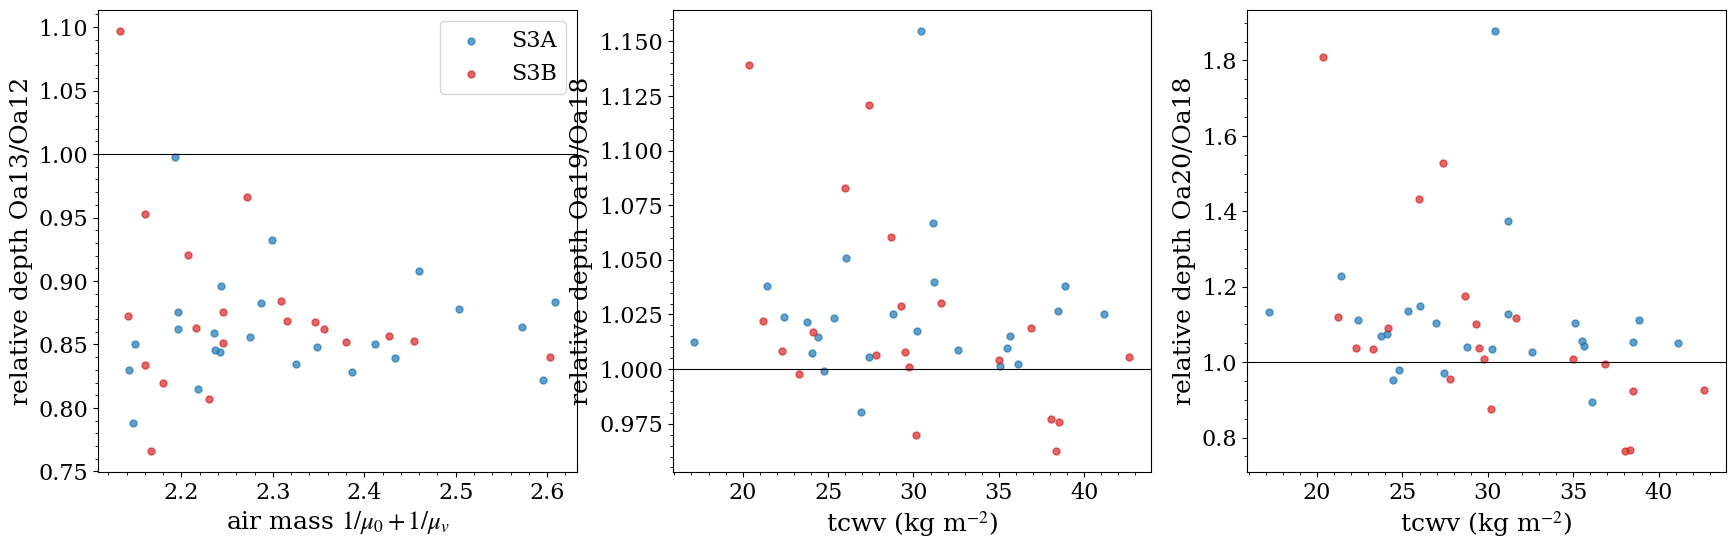

In [21]:
air_mass = 1 / np.cos(np.radians(mu.sza)) + 1 / np.cos(np.radians(mu.vza))
fig, axs = plt.subplots(1, 3, figsize=(21, 6))
for ax, pair, x, xlab in ((axs[0], 'Oa13/Oa12', air_mass, 'air mass $1/\\mu_0 + 1/\\mu_v$'),
                          (axs[1], 'Oa19/Oa18', mu.tcwv, r'tcwv (kg m$^{-2}$)'),
                          (axs[2], 'Oa20/Oa18', mu.tcwv, r'tcwv (kg m$^{-2}$)')):
    for p, c in PLATFORMS.items():
        sel = mu.platform.values == p
        ax.scatter(x.values[sel], depth.sel(pair=pair).values[sel], color=c, s=25, alpha=0.7, label=p)
    ax.axhline(1, color='k', lw=0.8)
    ax.set(xlabel=xlab, ylabel=f'relative depth {pair}')
    ax.minorticks_on()
axs[0].legend()
plt.show()

## 11. Flags and selections as uncertainty indicators

Each selection keeps the matchups for which an indicator is below a level; the change of the median and of the
robust SD of the ratio says how much that indicator contributes to the uncertainty of the comparison. The
selections of the Sentinel-2 statements (`scripts/radcalnet_products/statement_figures.py`) are reproduced:

* `angle30`: glint angle > 30°;
* `nohigh`: no `glint_high` nor `glint_near_specular` flag;
* `noglint`: no `glint_moderate`, `glint_high` nor `glint_near_specular` flag;
* `noglint + mask`: `noglint` and the bands flagged `glint_uncertain` masked;

and the other indicators: viewing zenith angle below 40° (dense LUT nodes, low air mass), AOT(550) < 0.2,
level 2.0 only, $R_{rs}$ reconstruction residual below its 75th percentile, nearest AERONET-OC measurement within
30 min, box without the platform pixel. The glint fraction of OLCI is typically larger than for MSI (wider swath,
glint side of the orbits), so the glint selections remove more matchups than at Sentinel-2.

In [22]:
def flag(m, names):
    return (m.glint_flags.astype(int) & sum(radoc.GLINT_FLAGS[n] for n in names)) > 0


SELECTIONS = {
    'all': lambda m: xr.ones_like(m.sza, dtype=bool),
    'angle30': lambda m: m.glint_angle > 30,
    'nohigh': lambda m: ~flag(m, ['glint_high', 'glint_near_specular']),
    'noglint': lambda m: ~flag(m, ['glint_moderate', 'glint_high', 'glint_near_specular']),
    'vza<40': lambda m: m.vza < 40,
    'aot550<0.2': lambda m: m.aot550 < 0.2,
    'level 2.0': lambda m: m.level >= 2,
    'Rrs rmsd < q75': lambda m: m.rrs_rmsd <= m.rrs_rmsd.quantile(0.75),
    '|dt| < 30 min': lambda m: np.abs(m.dt_min) < 30,
}


def selection_table(m, bands=('Oa03', 'Oa06', 'Oa08', 'Oa12', 'Oa17', 'Oa18')):
    rows = []
    for site in np.unique(m.site.values):
        ms = subset(m, m.site == site)
        cases = [(name, f(ms), 'ratio', False) for name, f in SELECTIONS.items()]
        cases += [('noglint + mask', SELECTIONS['noglint'](ms), 'ratio', True),
                  ('no platform pixel', xr.ones_like(ms.sza, dtype=bool), 'ratio_nocentre', False),
                  ('reflectance (OLCI F0)', xr.ones_like(ms.sza, dtype=bool), 'ratio_refl', False)]
        for name, sel, var, mask in cases:
            x = ms.isel(time=np.flatnonzero(sel.values))
            row = {'site': site, 'selection': name, 'N': x.sizes['time']}
            for b in bands:
                y = x[var].sel(band=b)
                if mask:
                    y = y.where(x.glint_uncertain.sel(band=b) == 0)
                med, s, n = robust(y.values)
                row[f'{b} median'] = med
                row[f'{b} rsd_%'] = 100 * s
            rows.append(row)
    return pd.DataFrame(rows).set_index(['site', 'selection'])


selections = selection_table(mu)
selections.round(3)

N  Oa03 median  Oa03 rsd_%  Oa06 median  \
site selection                                                         
VEIT all                    44        1.022       3.136        1.022   
     angle30                34        1.022       2.290        1.022   
     nohigh                 34        1.022       2.290        1.022   
     noglint                31        1.022       2.337        1.022   
     vza<40                 41        1.022       3.014        1.022   
     aot550<0.2             33        1.024       2.303        1.025   
     level 2.0              44        1.022       3.136        1.022   
     Rrs rmsd < q75         33        1.022       2.476        1.022   
     |dt| < 30 min          40        1.018       3.058        1.021   
     noglint + mask         31        1.022       2.337        1.022   
     no platform pixel      44        1.022       3.121        1.022   
     reflectance (OLCI F0)  44        1.020       3.134        1.021   

                            Oa06 rsd_%  Oa08 median  Oa08 rsd_%  Oa12 median  \
site selection                                                                 
VEIT all                         3.839        1.039       5.711        1.102   
     angle30                     2.645        1.039       4.537        1.102   
     nohigh                      2.645        1.039       4.537        1.102   
     noglint                     2.592        1.040       4.596        1.107   
     vza<40                      4.033        1.033       6.719        1.094   
     aot550<0.2                  2.993        1.061       5.684        1.119   
     level 2.0                   3.839        1.039       5.711        1.102   
     Rrs rmsd < q75              3.707        1.050       5.846        1.119   
     |dt| < 30 min               3.607        1.030       6.344        1.093   
     noglint + mask              2.592        1.040       4.596        1.103   
     no platform pixel           3.743        1.038       5.514        1.104   
     reflectance (OLCI F0)       3.795        1.038       5.729        1.101   

                            Oa12 rsd_%  Oa17 median  Oa17 rsd_%  Oa18 median  \
site selection                                                                 
VEIT all                         7.821        1.165      10.666        1.180   
     angle30                     6.998        1.171       9.627        1.188   
     nohigh                      6.998        1.171       9.627        1.188   
     noglint                     6.426        1.177       8.912        1.198   
     vza<40                      8.417        1.159      11.451        1.180   
     aot550<0.2                  7.939        1.168      11.500        1.180   
     level 2.0                   7.821        1.165      10.666        1.180   
     Rrs rmsd < q75             10.635        1.168      11.534        1.180   
     |dt| < 30 min               8.374        1.156      10.390        1.176   
     noglint + mask              6.572        1.175       7.510        1.196   
     no platform pixel           7.901        1.164      10.720        1.182   
     reflectance (OLCI F0)       7.891        1.163      10.719        1.178   

                            Oa18 rsd_%  
site selection                          
VEIT all                        11.878  
     angle30                     9.930  
     nohigh                      9.930  
     noglint                     9.795  
     vza<40                     12.114  
     aot550<0.2                 12.517  
     level 2.0                  11.878  
     Rrs rmsd < q75             12.570  
     |dt| < 30 min              11.516  
     noglint + mask              8.449  
     no platform pixel          12.160  
     reflectance (OLCI F0)      11.805

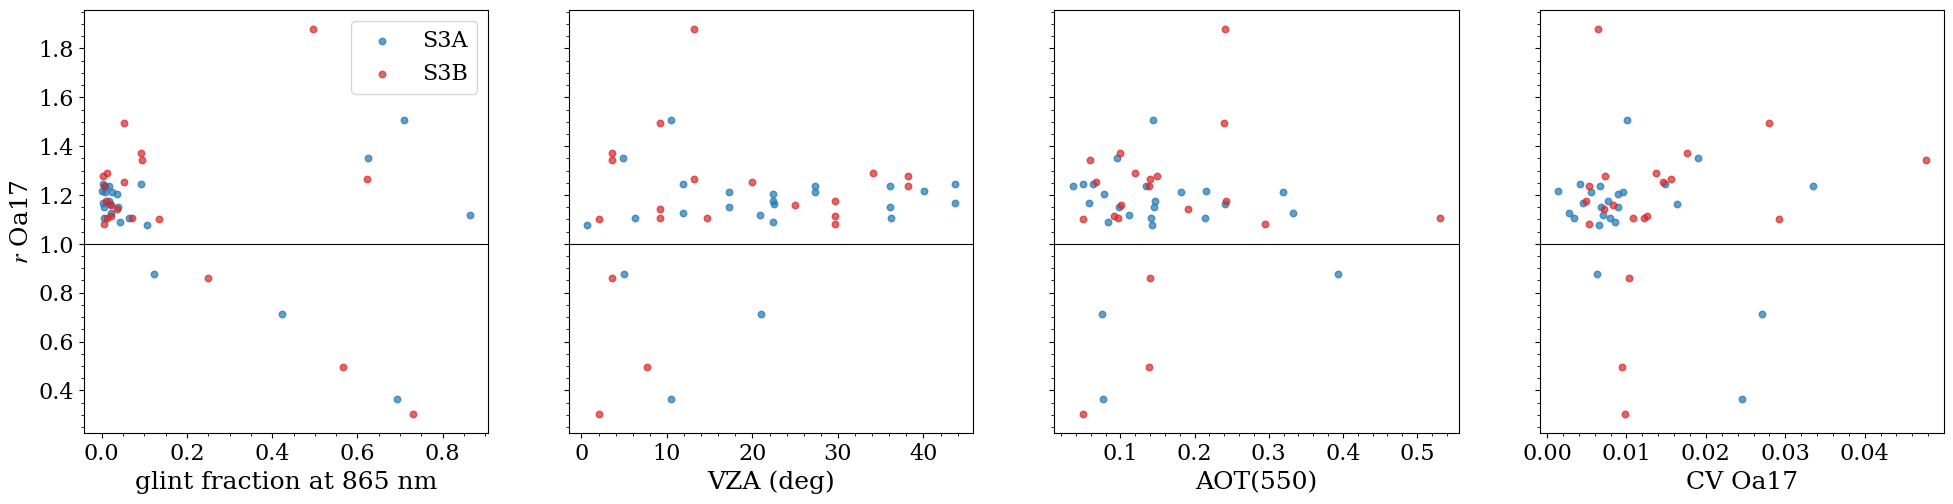

In [23]:
def plot_indicators(m, band='Oa17'):
    x = m.sel(band=band)
    fig, axs = plt.subplots(1, 4, figsize=(24, 5.5), sharey=True)
    for ax, v, lab in zip(axs, ['glint_fraction', 'vza', 'aot550', 'cv'],
                          ['glint fraction at 865 nm', 'VZA (deg)', 'AOT(550)', f'CV {CV_BAND}']):
        for p, c in PLATFORMS.items():
            sel = x.platform.values == p
            ax.scatter(x[v].values[sel], x.ratio.values[sel], color=c, s=22, alpha=0.7, label=p)
        ax.axhline(1, color='k', lw=0.8)
        ax.set_xlabel(lab)
        ax.minorticks_on()
    axs[0].set_ylabel(f'$r$ {band}')
    axs[0].legend()
    plt.show()


plot_indicators(mu)

## 12. Export

The matchup dataset (OLCI box statistics, simulation statistics and uncertainty terms, flags, geometry, platform and
site of each scene) is written to netCDF with the settings of the simulation, and the monitoring tables to CSV.

In [24]:
if SAVE:
    os.makedirs(ODIR, exist_ok=True)
    tag = f'{"-".join(SITE_CODES)}_{pd.Timestamp(PERIOD.start):%Y%m%d}-{pd.Timestamp(PERIOD.stop):%Y%m%d}'
    out = mu.copy()
    for v in ['site', 'platform', 'product', 'glint_level']:
        out[v] = out[v].astype(str)
    out.attrs = {**{k: str(v) for k, v in SETTINGS.items()},
                 'description': 'Sentinel-3 OLCI L1 radiance (box around the station) vs RadCalNet-OC simulations of '
                                'the AERONET-OC measurements within +/- DELTA_TIME at the geometry of each scene, '
                                'with the direct sunglint; radiance in mW m-2 sr-1 nm-1',
                 'delta_time_min': int(DELTA_TIME / np.timedelta64(1, 'm')), 'vza_max': VZA_MAX,
                 'max_cv': MAX_CV, 'max_cloud_fraction': MAX_CLOUD_FRACTION, 'ocm': int(USE_OCM),
                 'srf': os.path.basename(SRF_FILE) + ' shifted to the detector lambda0'}
    ofile = opj(ODIR, f'olci_radcalnet-oc_v{radoc.__version__}_{tag}_matchup.nc')
    out.time.encoding.update(units='seconds since 2016-01-01', dtype='float64')
    out.to_netcdf(ofile)
    monitoring.to_csv(ofile.replace('_matchup.nc', '_monitoring.csv'), index=False)
    selections.to_csv(ofile.replace('_matchup.nc', '_selections.csv'))
    print(ofile)

<quick-run test folder, S3_CALVAL_ODIR>/olci_radcalnet-oc_v1.2.0_VEIT_20200601-20200831_matchup.nc


## 13. Notes and open issues

* **Spectral responses of S3B.** Only the S3A camera-mean responses are in the repository; S3B uses their shape
  shifted to its detector $\lambda_0$. The S3B characterisation (ESA/EUMETSAT, `S3B_OL_SRF_*_mean_rsr.nc4`) would
  remove this approximation, mostly relevant in Oa13-Oa15 and Oa19-Oa20.
* **Model gap.** `u_model` comes from the Sentinel-2 matchups (VEIT and CORO, viewing zenith < 12°); at the OLCI
  viewing angles (up to 48°) it is extrapolated. The OLCI matchups could provide their own model-gap table once
  the full multi-year run is available (same method as `residual_budget.py --model-table`), but it must not be
  tuned on the same matchups used to assess OLCI.
* **Budget per scene.** The budget is computed for the measurement nearest to the overpass and applied in
  relative terms to the window; the temporal variability is added separately.
* **OLCI radiometric uncertainty.** `radiance_unc` is read as $\log_{10}$ of the standard uncertainty (unit
  "lg(re mW m-2 sr-1 nm-1)" of the L1 product), about 2 % in the visible.
* **Platform pixel at 300 m.** Kept by default; its effect is the `no platform pixel` row of section 11.
* **Drift.** The trends are not corrected for the seasonal cycle of the geometry and of the glint, nor for the
  change of AERONET-OC station at VEIT (Venise to AAOT).